# NLP Sentiment Analysis — Exploratory Data Analysis

## Business Objective

The objective of this project is to analyze customer product reviews
and extract the sentiment expressed in those reviews.

The project focuses on customer review text collected from e-commerce
sources.

## EDA Objectives

The main objectives of this EDA are:

1. Understand the structure and quality of the dataset.
2. Analyze customer rating distribution.
3. Create initial sentiment labels from customer ratings.
4. Analyze review length and text characteristics.
5. Clean and preprocess review text.
6. Analyze sentiment using NLTK VADER.
7. Analyze frequently occurring words and phrases.
8. Analyze parts of speech and adjectives.
9. Compare rating-based sentiment with text-based VADER sentiment.
10. Identify useful insights for subsequent model building.

#### ***IMPORT LIBRARIES***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import spacy
import warnings
warnings.filterwarnings('ignore')

from textblob import TextBlob
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer

#### ***READ THE DATASET***

In [2]:
df = pd.read_excel('dataset.xlsx')

#### ***CHECK THE FIRST 5 RECORD FROM DATASET***

In [3]:
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


#### ***CHECK THE SHAPE (ROWS AND COLUMNS) OF THE DATASET***

In [4]:
df.shape

(1440, 3)

#### ***CHECK THE COLUMNS IN DATASET***

In [5]:
df.columns

Index(['title', 'rating', 'body'], dtype='object')

#### ***iNFORMATION OF DATASET***

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


#### ***STATISTICAL SUMMARY***

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
rating,1440.0,3.173611,1.584453,1.0,1.0,4.0,5.0,5.0


- .T transposes the output, making it easier to read.

#### ***CHECK MISSING VALUE***

In [8]:
df.isnull().sum()

title     0
rating    0
body      0
dtype: int64

#### ***MISSING VALUE IN PERCENTAGE***

In [9]:
df.isnull().sum() / len(df) * 100

title     0.0
rating    0.0
body      0.0
dtype: float64

- I checked missing values both as counts and percentages to understand their impact relative to the dataset size.

#### ***CHECK EMPTY STRING***

In [10]:
empty_strings = (df[["title", "body"]] == "").sum()
print("Empty strings:")
print(empty_strings)

Empty strings:
title    0
body     0
dtype: int64


In [11]:
print("Empty titles:", (df["title"].str.strip() == "").sum())
print("Empty review bodies:", (df["body"].str.strip() == "").sum())

Empty titles: 0
Empty review bodies: 0


#### ***CHECK DUPLICATE VALUES***

In [12]:
df.duplicated().sum()

np.int64(0)

#### ***DUPLICATE-TEXT ANALYSIS***

In [13]:
print("Duplicate review texts:", df["body"].duplicated().sum())

Duplicate review texts: 0


In [14]:
print("Duplicate title + body:", df.duplicated(subset = ["title", "body"]).sum())

Duplicate title + body: 0


#### ***CHECK RATING VALUES***

In [15]:
print("Unique ratings:", sorted(df["rating"].unique()))
invalid_ratings = df[~df["rating"].isin([1, 2, 3, 4, 5])]
print("Invalid ratings:", len(invalid_ratings))

Unique ratings: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Invalid ratings: 0


- The rating column was validated to ensure that every rating belongs to the expected 1–5 scale. No invalid rating values were found

#### ***RATING DISTRIBUTION***

In [16]:
df['rating'].value_counts()

rating
5    419
1    386
4    310
3    199
2    126
Name: count, dtype: int64

- Counts how many reviews have each rating.
- This tells you whether the dataset is balanced or dominated by particular ratings.

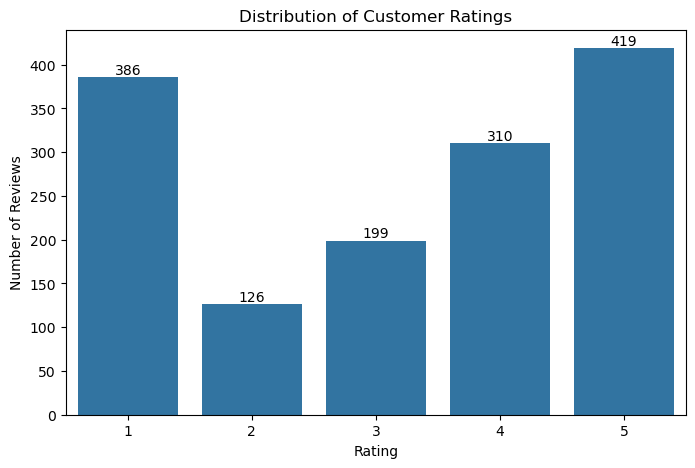

In [17]:
plt.figure(figsize = (8, 5))
ax = sns.countplot(data = df, x = 'rating', order = [1, 2, 3, 4, 5])
plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')

for container in ax.containers:
    ax.bar_label(container)
    
plt.show()

- Creates a bar chart showing the number of reviews for each rating.

#### ***RATING PERCENTAGE***

In [18]:
rating_percentage = (df['rating'].value_counts(normalize = True).sort_index() * 100)
display(rating_percentage.round(2).rename("Percentage"))

rating
1    26.81
2     8.75
3    13.82
4    21.53
5    29.10
Name: Percentage, dtype: float64

- Calculates the percentage of reviews for each rating.

#### ***CREATE SENTIMENT LABELS***

In [19]:
def create_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    elif rating >= 4:
        return 'Positive'
    else:
        return np.nan

df['sentiment'] = df['rating'].apply(create_sentiment)

- Since the dataset does not provide explicit sentiment labels, rating-based sentiment was created as an initial proxy. Ratings 1–2 were mapped to Negative, rating 3 to Neutral, and ratings 4–5 to Positive. These labels provide a reference for exploratory analysis but should not be treated as perfect ground-truth sentiment labels.

In [20]:
df[['rating', 'sentiment']].head(20)

,rating,sentiment
0,1,Negative
1,3,Neutral
2,4,Positive
3,1,Negative
4,1,Negative
5,1,Negative
6,1,Negative
7,1,Negative
8,1,Negative
9,1,Negative


#### ***SENTIMENT DISTRIBUTION***

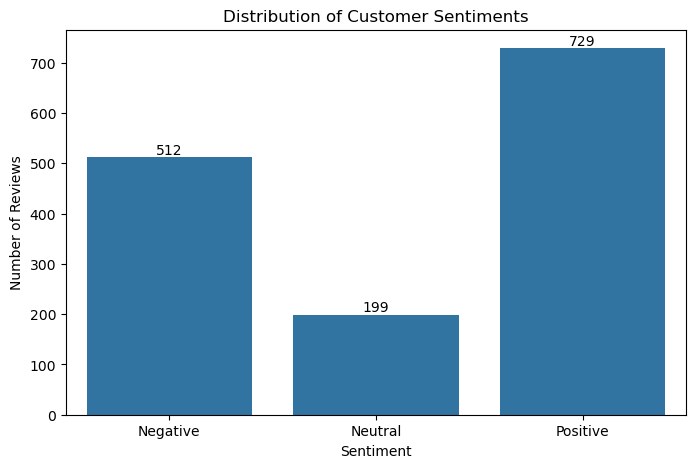

In [21]:
plt.figure(figsize = (8, 5))
ax = sns.countplot(data = df, x = 'sentiment', order = ['Negative', 'Neutral', 'Positive'])
plt.title('Distribution of Customer Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

- Visualizes how many reviews belong to each sentiment category.

#### ***SENTIMENT PERCENTAGE***

In [22]:
sentiment_percentage = (df['sentiment'].value_counts(normalize = True) * 100)
sentiment_percentage.round(2).rename("Percentage")

sentiment
Positive    50.62
Negative    35.56
Neutral     13.82
Name: Percentage, dtype: float64

- Shows the percentage of Negative, Neutral and Positive reviews.
- Useful for explaining the overall sentiment composition.

#### ***RATING VS SENTIMENT VALIDATION***

In [23]:
rating_sentiment_table = pd.crosstab(df["rating"], df["sentiment"])
rating_sentiment_table

sentiment,Negative,Neutral,Positive
rating,,,
1,386,0,0
2,126,0,0
3,0,199,0
4,0,0,310
5,0,0,419


- It verifies that your sentiment mapping is working correctly.

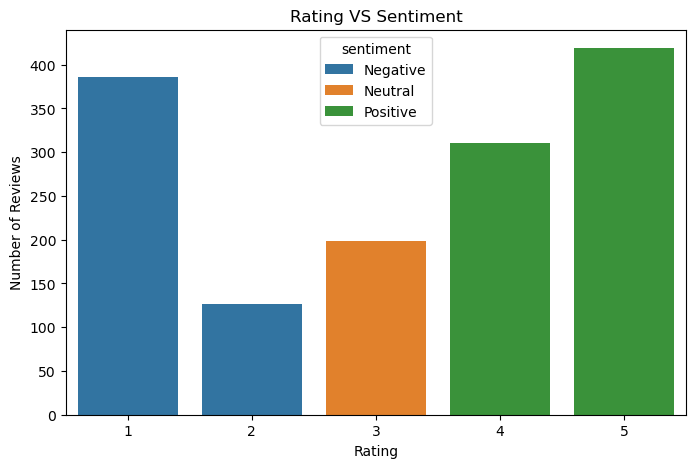

In [24]:
plt.figure(figsize = (8, 5))
sns.countplot(data = df, x = 'rating', hue = 'sentiment', order = [1, 2, 3, 4, 5])
plt.title('Rating VS Sentiment')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.show()

- Relationship between:- Rating → Sentiment

#### ***COMBINE TITLE AND REVIEW BODY***

In [25]:
df['title'] = df['title'].fillna('').astype(str)
df['body'] = df['body'].fillna('').astype(str)
df['text'] = (df['title'].str.strip() + " " + df['body'].str.strip()).str.strip()

- The review title and review body were combined into a single text field because both components can contain sentiment-bearing information. The resulting text column represents the complete customer review and is used for subsequent NLP analysis.

In [26]:
df[['title', 'body', 'text']].head()

,title,body,text
0,Horrible product,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...
1,Camera quality is not like 48 megapixel,Camera quality is low,Camera quality is not like 48 megapixel Camera...
2,Overall,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt..."
3,A big no from me,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...
4,Put your money somewhere else,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...


- Allows you to verify that title and body were combined correctly.

#### ***REVIEW LENGTH ANALYSIS***

In [27]:
df['character_count'] = df['text'].apply(len)
df['word_count'] =  df['text'].apply(lambda x: len(x.split()))

In [28]:
df[['text', 'character_count', 'word_count']].head()

,text,character_count,word_count
0,Horrible product Very disappointed with the ov...,76,10
1,Camera quality is not like 48 megapixel Camera...,61,11
2,"Overall Got the mobile on the launch date,Batt...",411,67
3,A big no from me 1. It doesn't work with 5.0GH...,394,72
4,Put your money somewhere else Not worth buying...,209,34


- Review length was analyzed using both character count and word count. The average review contains approximately 58 words and 333 characters, while the median is lower, indicating that some longer reviews increase the average. The maximum review length also indicates the presence of relatively long reviews.

#### ***REVIEW LENGTH STATISTICS***

In [29]:
df[['character_count', 'word_count']].describe().T

,count,mean,std,min,25%,50%,75%,max
character_count,1440.0,333.381944,229.116704,9.0,198.0,277.0,395.0,2536.0
word_count,1440.0,58.257639,39.896874,2.0,34.0,49.0,70.0,391.0


#### ***REVIEW WORD COUNT DISTRIBUTION***

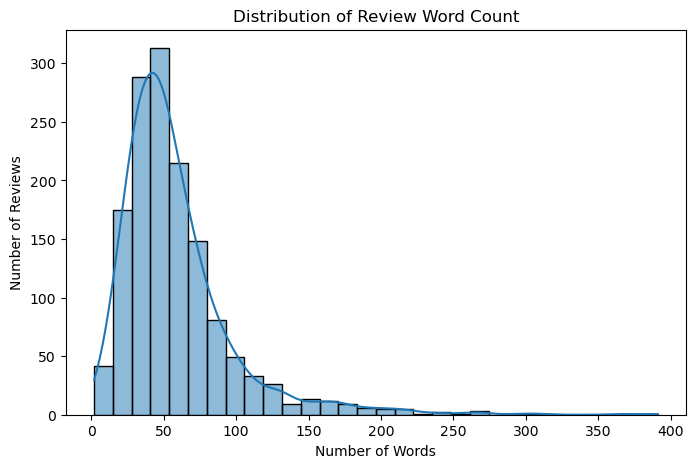

In [30]:
plt.figure(figsize = (8, 5))
sns.histplot(data = df, x = 'word_count', kde = True, bins = 30)
plt.title('Distribution of Review Word Count')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')
plt.show()

- Creates a histogram of review lengths.

#### ***REVIEW CHARACTER COUNT DISTRIBUTION***

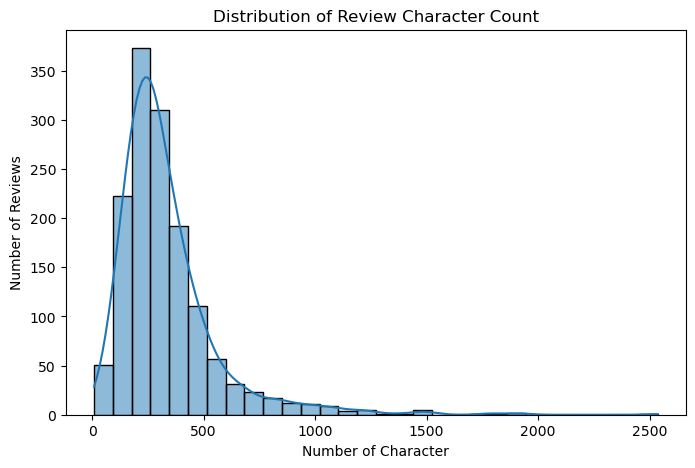

In [31]:
plt.figure(figsize = (8, 5))
sns.histplot(data = df, x = 'character_count', kde = True, bins = 30)
plt.title('Distribution of Review Character Count')
plt.xlabel('Number of Character')
plt.ylabel('Number of Reviews')
plt.show()

#### ***REVIEW LENGTH BY RATING***

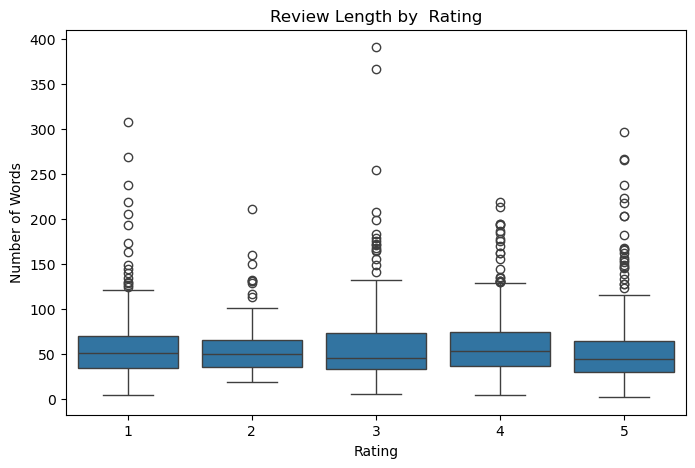

In [32]:
plt.figure(figsize = (8, 5))
sns.boxplot(data = df, x = 'rating', y = 'word_count', order = [1, 2, 3, 4, 5])
plt.title('Review Length by  Rating')
plt.xlabel('Rating')
plt.ylabel('Number of Words')
plt.show()

- Review length varies across sentiment categories, but the average word counts are relatively similar. Therefore, sentiment does not appear to be strongly associated with overall review length in this dataset.

#### ***REVIEW LENGTH BY SENTIMENT***

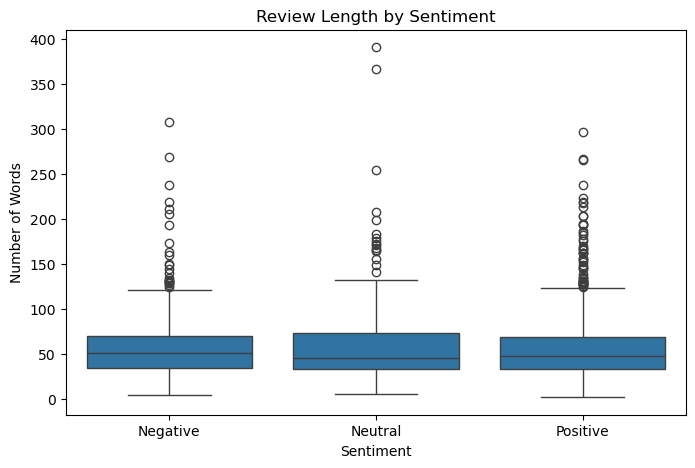

In [33]:
plt.figure(figsize = (8, 5))
sns.boxplot(data = df, x = 'sentiment', y = 'word_count', order = ['Negative', 'Neutral', 'Positive'])
plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Words')
plt.show()

- Compares review length among:
    - Negative
    - Neutral
    - Positive

#### ***INITIALIZE NLTK AND spaCY***

In [34]:
stop_words = set(stopwords.words('english'))
negation_words = {'no','not','nor','neither','never','none','cannot'}
stop_words = stop_words - negation_words
nlp = spacy.load('en_core_web_sm')
vader = SentimentIntensityAnalyzer()

- Loads common English stopwords.
- Loads spaCy's English language model.
- It can perform:
    - tokenization
    - lemmatization
    - POS tagging
    - linguistic analysis
* Creates the NLTK VADER sentiment analyzer.

In [35]:
contractions = {
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "can't": "can not",
    "couldn't": "could not",
    "won't": "will not",
    "wouldn't": "would not",
    "shouldn't": "should not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "haven't": "have not",
    "hasn't": "has not",
    "hadn't": "had not",
    "mustn't": "must not"
}

#### ***CREATE NLP TEXT CLEANING FUNCTION***

In [36]:
def clean_text(text):
    text = str(text).lower()

    for key, value in contractions.items():
        text = text.replace(key, value) # Expand contractions
    
    text = re.sub(r"http\S+", "", text) # Remove URLs
    text = re.sub(r"[^a-zA-Z0-9 ]", " ", text) # Keep letters and numbers
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words] # Remove stopwords but keep negations
    doc = nlp(" ".join(tokens)) # spaCy Lemmatization
    lemmas = []

    for token in doc:
        if not token.is_space:
            lemmas.append(token.lemma_)

    return " ".join(lemmas)

- Text preprocessing included lowercasing, contraction expansion, URL removal, punctuation cleaning, stopword removal, negation preservation, and lemmatization. Negation terms such as "not", "never", and "no" were intentionally retained because they carry important sentiment information.

#### ***APPLY TEXT CLEANING***

In [37]:
df['clean_text'] = df['text'].apply(clean_text)

In [38]:
df[['text', 'clean_text']].head(20)

,text,clean_text
0,Horrible product Very disappointed with the ov...,horrible product disappoint overall performanc...
1,Camera quality is not like 48 megapixel Camera...,camera quality not like 48 megapixel camera qu...
2,"Overall Got the mobile on the launch date,Batt...",overall get mobile launch date battery must ap...
3,A big no from me 1. It doesn't work with 5.0GH...,big no 1 not work 5 0ghz wifi frequency 2 4ghz...
4,Put your money somewhere else Not worth buying...,put money somewhere else not worth buy faulty ...
5,Too much lagging and slow I will never purchas...,much lag slow never purchase samsung phone pho...
6,Worst samsung mobile ever This is worst samsun...,bad samsung mobile ever bad samsung mobile see...
7,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...,10 48 pm 5
8,Slow performance The phone hangs a lot and is ...,slow performance phone hang lot slow receive r...
9,Don’t buy from Amazon. Very poor quality camer...,buy amazon poor quality camera find box seal d...


#### ***NLTK STOPWORDS CHECK***

In [39]:
print("Number of NLTK English stopwords:", len(stop_words))

print("\nSample stopwords:")
print(list(stop_words)[:20])

Number of NLTK English stopwords: 195

Sample stopwords:
['haven', 'shouldn', 'are', "don't", 'off', 'should', "you'd", 'but', 'her', 'will', 'where', 'wasn', "i'll", 'did', 'my', 'what', 'with', 'was', 'it', 'theirs']


#### ***REVIEW WORD COUNT AFTER CLEANING***

In [40]:
df["clean_word_count"] = df["clean_text"].apply(lambda x: len(x.split()))
df[["word_count", "clean_word_count"]].head()

,word_count,clean_word_count
0,10,6
1,11,9
2,67,39
3,72,45
4,34,30


#### ***CHECK EMPTY REVIEW AFTER CLEANING***

In [41]:
empty_reviews = df[df["clean_text"].str.strip() == ""]
print("Empty reviews after cleaning:", len(empty_reviews))

Empty reviews after cleaning: 2


In [42]:
empty_reviews[["title", "rating", "body"]].head()

,title,rating,body
460,असंतोषजनक,1,इस फोन में कई कमियां है जैसे इसकी नोटिफिकेशन ट...
794,इस फोन में बहुत सारे प्रॉब्लम है,1,इस फोन में बहुत सारे प्रॉब्लम है चार्ज में लगा...


#### ***VADER SENTIMENT ANALYSIS***

In [43]:
def get_vader_score(text):
    scores = vader.polarity_scores(str(text))
    return pd.Series({
        'vader_negative': scores['neg'],
        'vader_neutral': scores['neu'],
        'vader_positive': scores['pos'],
        'vader_compound': scores['compound']
    })

In [44]:
vader_scores = df['text'].apply(get_vader_score)
df = pd.concat([df, vader_scores], axis = 1)

In [45]:
df[["text", "rating", "sentiment", "vader_negative", "vader_neutral", "vader_positive", "vader_compound"]].head(10)

,text,rating,sentiment,vader_negative,vader_neutral,vader_positive,vader_compound
0,Horrible product Very disappointed with the ov...,1,Negative,0.463,0.537,0.000,-0.7841
1,Camera quality is not like 48 megapixel Camera...,3,Neutral,0.319,0.681,0.000,-0.4956
2,"Overall Got the mobile on the launch date,Batt...",4,Positive,0.076,0.843,0.081,0.1027
3,A big no from me 1. It doesn't work with 5.0GH...,1,Negative,0.209,0.770,0.021,-0.9162
4,Put your money somewhere else Not worth buying...,1,Negative,0.235,0.765,0.000,-0.8033
5,Too much lagging and slow I will never purchas...,1,Negative,0.318,0.682,0.000,-0.7506
6,Worst samsung mobile ever This is worst samsun...,1,Negative,0.193,0.753,0.054,-0.7845
7,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...,1,Negative,0.000,1.000,0.000,0.0000
8,Slow performance The phone hangs a lot and is ...,1,Negative,0.000,1.000,0.000,0.0000
9,Don’t buy from Amazon. Very poor quality camer...,1,Negative,0.236,0.579,0.185,-0.6361


- VADER is particularly effective for customer reviews because it is designed to capture sentiment intensity in short informal text. The compound score ranges from -1 to +1 and summarizes overall sentiment.

#### ***UNDERSTAND VADER COMPOUND SCORE***

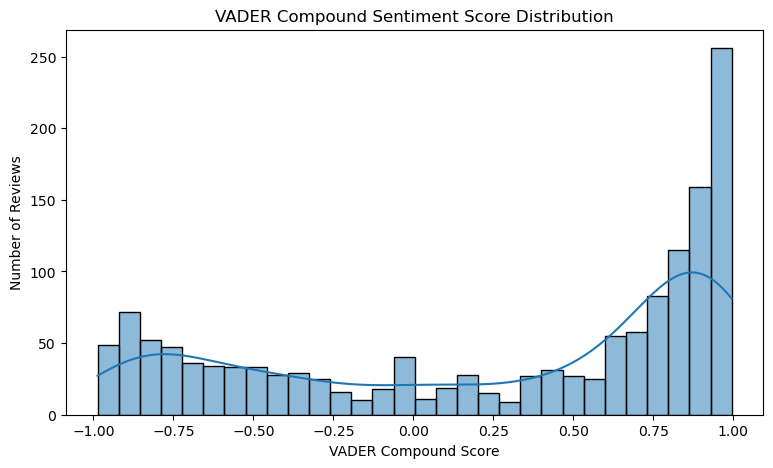

In [46]:
plt.figure(figsize = (9, 5))
sns.histplot(data = df, x = "vader_compound", bins = 30, kde = True)
plt.title("VADER Compound Sentiment Score Distribution")
plt.xlabel("VADER Compound Score")
plt.ylabel("Number of Reviews")
plt.show()

#### ***CREATE VADER SENTIMENT CATEGORY***

In [47]:
def vader_category(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["vader_sentiment"] = df["vader_compound"].apply(vader_category)

In [48]:
df[["rating", "sentiment", "vader_compound", "vader_sentiment"]].head(15)

,rating,sentiment,vader_compound,vader_sentiment
0,1,Negative,-0.7841,Negative
1,3,Neutral,-0.4956,Negative
2,4,Positive,0.1027,Positive
3,1,Negative,-0.9162,Negative
4,1,Negative,-0.8033,Negative
5,1,Negative,-0.7506,Negative
6,1,Negative,-0.7845,Negative
7,1,Negative,0.0000,Neutral
8,1,Negative,0.0000,Neutral
9,1,Negative,-0.6361,Negative


#### ***COMPARE RATING-BASED SENTIMENT VS VADER***

In [49]:
comparison_table = pd.crosstab(df["sentiment"], df["vader_sentiment"])
comparison_table

vader_sentiment,Negative,Neutral,Positive
sentiment,,,
Negative,361,21,130
Neutral,81,6,112
Positive,45,17,667


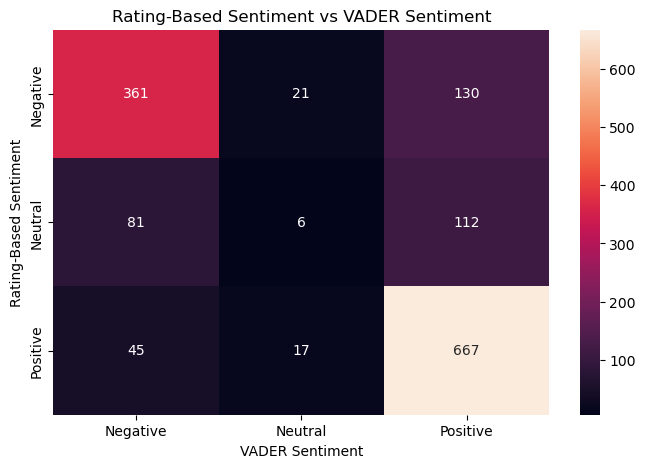

In [50]:
plt.figure(figsize = (8, 5))
sns.heatmap(comparison_table, annot = True,fmt = "d")
plt.title("Rating-Based Sentiment vs VADER Sentiment")
plt.xlabel("VADER Sentiment")
plt.ylabel("Rating-Based Sentiment")
plt.show()

#### ***VADER SCORE BY RATING***

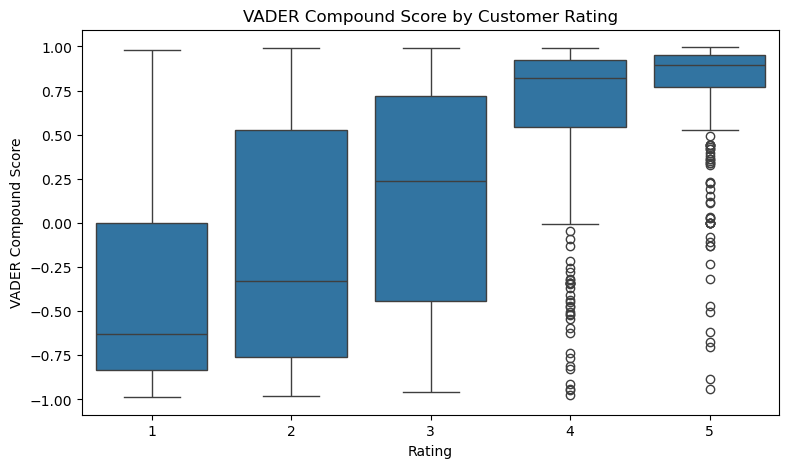

In [51]:
plt.figure(figsize = (9, 5))
sns.boxplot(data = df, x = "rating", y = "vader_compound", order = [1, 2, 3, 4, 5])
plt.title("VADER Compound Score by Customer Rating")
plt.xlabel("Rating")
plt.ylabel("VADER Compound Score")
plt.show()

#### ***VADER SCORE BY RATING -- AVERAGE***

In [52]:
vader_by_rating = (df.groupby("rating")["vader_compound"].mean())
vader_by_rating.round(3)

rating
1   -0.401
2   -0.138
3    0.140
4    0.632
5    0.785
Name: vader_compound, dtype: float64

- VADER is a rule-based sentiment analysis tool designed to capture sentiment intensity in text. It produces negative, neutral, positive, and compound scores. The compound score ranges from -1 to +1 and summarizes the overall sentiment polarity.

#### ***MOST COMMON WORDS***

In [53]:
vectorizer = CountVectorizer(stop_words = "english")
X_words = vectorizer.fit_transform(df["clean_text"])
word_counts = np.asarray(X_words.sum(axis = 0)).ravel()
words = vectorizer.get_feature_names_out()
word_frequency = pd.DataFrame({
    "word": words,
    "count": word_counts
})

top_words = (word_frequency.sort_values("count", ascending = False).head(20))
display(top_words)

,word,count
3179,phone,2003
1938,good,1693
899,camera,1098
680,battery,892
3751,samsung,807
3447,quality,723
2792,mobile,645
4490,use,591
880,buy,526
3334,price,467


- The most frequent words indicate that customers primarily discuss core smartphone attributes such as phone quality, camera, battery, display, price, and overall product experience.

#### ***TOP 20 WORDS VISUALIZATION***

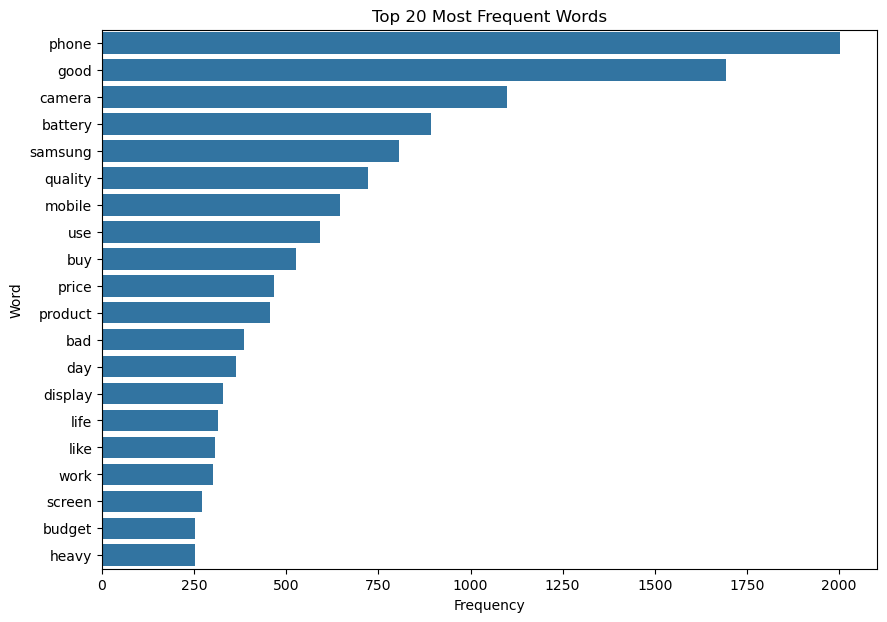

In [54]:
plt.figure(figsize = (10, 7))
sns.barplot(data = top_words, x = "count", y = "word")
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

#### ***TEXTBLOB SENTIMENT ANALYSIS***

In [55]:
def get_textblob_score(text):
    return TextBlob(str(text)).sentiment.polarity

df["textblob_polarity"] = df["text"].apply(get_textblob_score)
df[["text", "rating", "sentiment", "textblob_polarity"]].head(10)

,text,rating,sentiment,textblob_polarity
0,Horrible product Very disappointed with the ov...,1,Negative,-0.658333
1,Camera quality is not like 48 megapixel Camera...,3,Neutral,0.000000
2,"Overall Got the mobile on the launch date,Batt...",4,Positive,0.022222
3,A big no from me 1. It doesn't work with 5.0GH...,1,Negative,-0.004805
4,Put your money somewhere else Not worth buying...,1,Negative,0.029762
5,Too much lagging and slow I will never purchas...,1,Negative,-0.115278
6,Worst samsung mobile ever This is worst samsun...,1,Negative,-0.633333
7,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...,1,Negative,0.000000
8,Slow performance The phone hangs a lot and is ...,1,Negative,-0.345000
9,Don’t buy from Amazon. Very poor quality camer...,1,Negative,-0.160000


#### ***TEXTBLOB DISTRIBUTION***

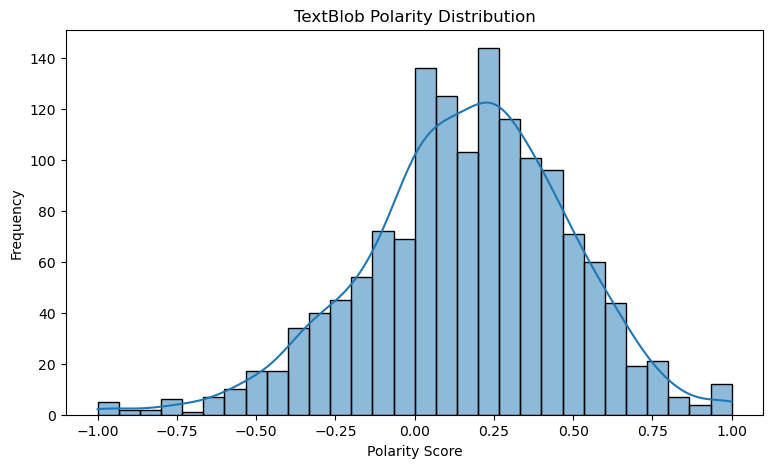

In [56]:
plt.figure(figsize = (9,5))
sns.histplot(data = df, x = "textblob_polarity", bins = 30, kde = True)
plt.title("TextBlob Polarity Distribution")
plt.xlabel("Polarity Score")
plt.ylabel("Frequency")
plt.show()

#### ***TEXTBLOB CATEGORY***

In [57]:
def textblob_category(score):
    if score > 0:
        return "Positive"
    elif score < 0:
        return "Negative"
    else:
        return "Neutral"

df["textblob_sentiment"] = (df["textblob_polarity"].apply(textblob_category))

#### ***RATING SENTIMENT VS TEXTBLOB***

In [58]:
comparison_tb = pd.crosstab(df["sentiment"], df["textblob_sentiment"])
comparison_tb

textblob_sentiment,Negative,Neutral,Positive
sentiment,,,
Negative,308,24,180
Neutral,52,6,141
Positive,21,8,700


#### ***HEATMAP***

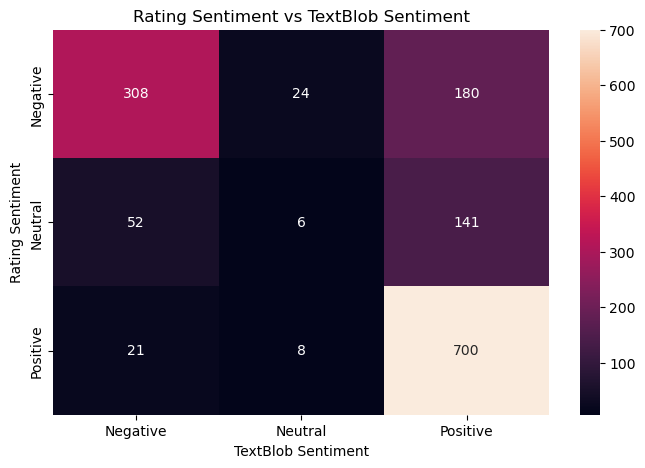

In [59]:
plt.figure(figsize = (8,5))
sns.heatmap(comparison_tb, annot = True, fmt = "d")
plt.title("Rating Sentiment vs TextBlob Sentiment")
plt.xlabel("TextBlob Sentiment")
plt.ylabel("Rating Sentiment")
plt.show()

#### ***TEXTBLOB VS VADER***

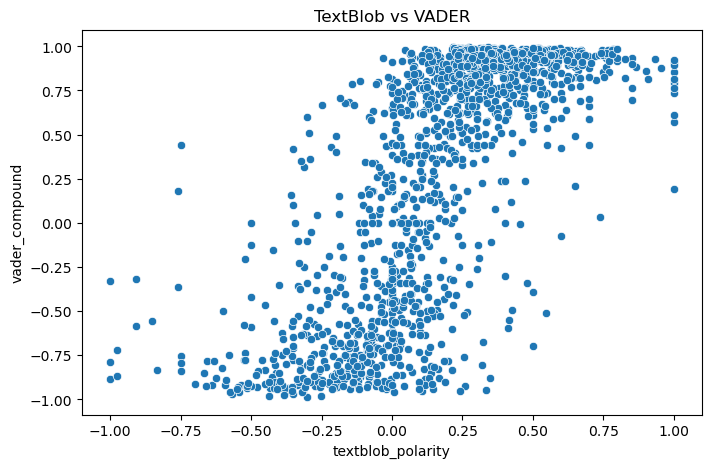

In [60]:
plt.figure(figsize = (8, 5))
sns.scatterplot(data = df, x = "textblob_polarity", y = "vader_compound")
plt.title("TextBlob vs VADER")
plt.show()

#### ***CORRELATION***

In [61]:
df[["textblob_polarity", "vader_compound"]].corr()

,textblob_polarity,vader_compound
textblob_polarity,1.000000,0.726857
vader_compound,0.726857,1.000000


- Comparing TextBlob and VADER helps identify whether different rule-based sentiment methods show similar or different patterns in the review dataset. Differences between the methods can also highlight reviews where sentiment is more difficult to classify.

#### ***TOP 20 BIGRAM***

In [62]:
bigram_vectorizer = CountVectorizer(stop_words = "english", ngram_range = (2,2))
X_bigram = (bigram_vectorizer.fit_transform(df["clean_text"]))
bigram_counts = np.asarray(X_bigram.sum(axis = 0)).ravel()
bigrams = (bigram_vectorizer.get_feature_names_out())

bigram_df = pd.DataFrame({
    "bigram": bigrams,
    "count": bigram_counts
})

top_bigrams = (bigram_df.sort_values(by = "count", ascending = False).head(20))
top_bigrams

,bigram,count
4178,camera quality,306
2743,battery life,281
9446,good phone,171
17903,price range,124
9215,good battery,121
18886,quality good,116
3529,budget phone,111
16645,phone good,99
3809,buy phone,98
25089,value money,95


- Bigram analysis identifies frequently occurring two-word phrases such as "battery life", "camera quality", and "charging issue". These phrases provide more meaningful business insights than individual words because they capture specific product attributes and customer concerns.

#### ***BIGRAM PLOT***

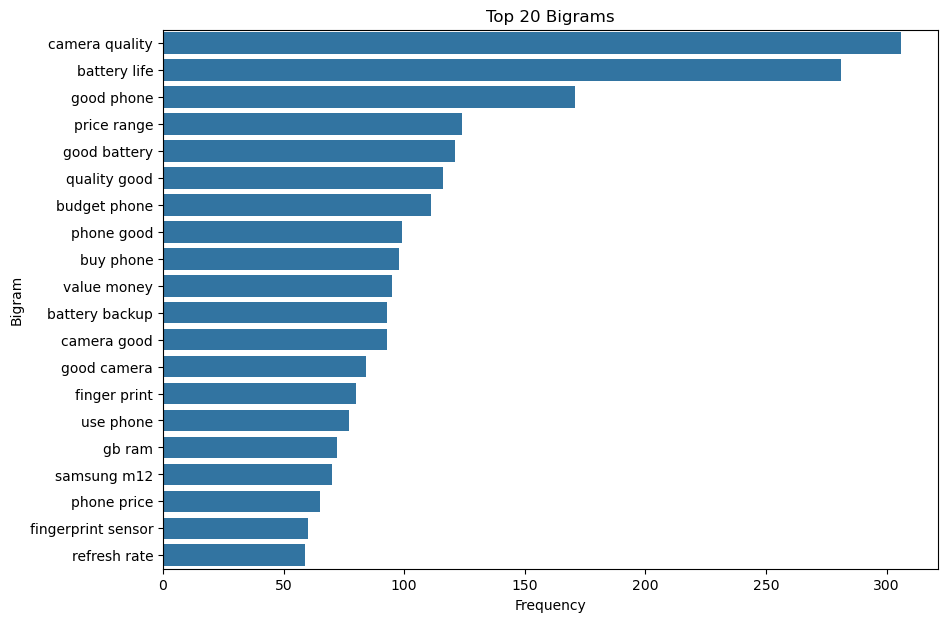

In [63]:
plt.figure(figsize = (10,7))
sns.barplot(data = top_bigrams, x = "count", y = "bigram")
plt.title("Top 20 Bigrams")
plt.xlabel("Frequency")
plt.ylabel("Bigram")
plt.show()

#### ***TOP 20 TRIGRAM***

In [64]:
trigram_vectorizer = CountVectorizer(stop_words = "english", ngram_range = (3,3))

X_trigram = (trigram_vectorizer.fit_transform(df["clean_text"]))
trigram_counts = np.asarray(X_trigram.sum(axis = 0)).ravel()
trigrams = (trigram_vectorizer.get_feature_names_out())
trigram_df = pd.DataFrame({
    "trigram": trigrams,
    "count": trigram_counts
})

top_trigrams = (trigram_df.sort_values(by = "count", ascending = False).head(20))
top_trigrams

,trigram,count
6187,camera quality good,62
3836,battery life good,57
12823,good battery life,45
29799,samsung galaxy m12,38
12865,good budget phone,37
6225,camera quality poor,34
11765,finger print reader,31
12920,good camera quality,27
23990,phone price range,25
12507,gb ram 128,24


- Trigram analysis identifies frequently occurring three-word phrases. These phrases provide more contextual information than individual words or bigrams and often reveal specific customer experiences or product issues.

#### ***TRIGRAM PLOT***

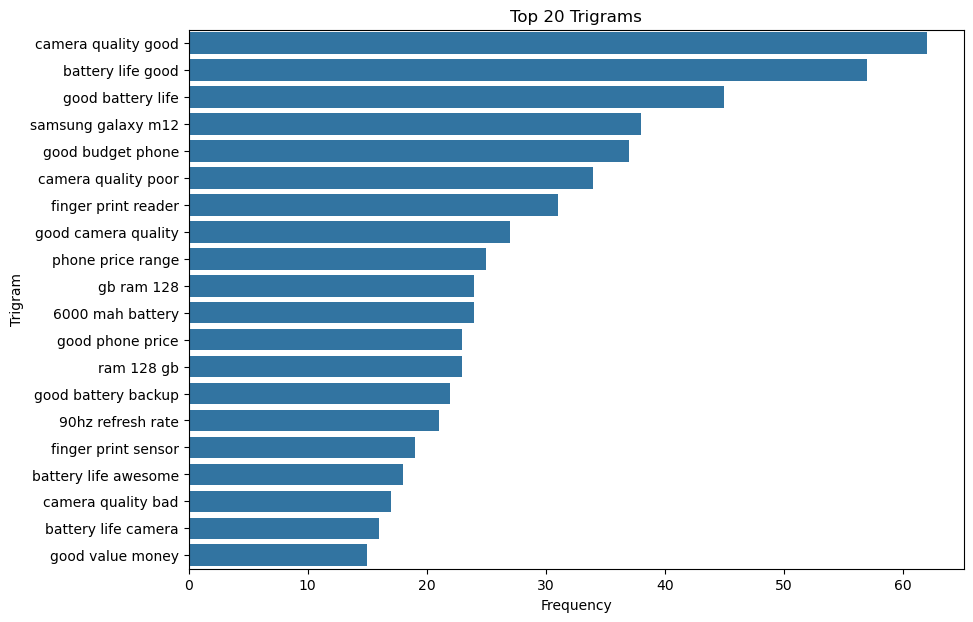

In [65]:
plt.figure(figsize = (10,7))
sns.barplot(data = top_trigrams, x = "count", y = "trigram")
plt.title("Top 20 Trigrams")
plt.xlabel("Frequency")
plt.ylabel("Trigram")
plt.show()

#### ***POS TAG ANALYSIS (spaCy)***

In [66]:
from collections import Counter
pos_tags = []
for text in df["clean_text"]:
    doc = nlp(text)
    for token in doc:
        pos_tags.append(token.pos_)
        
pos_counts = Counter(pos_tags)
pos_df = pd.DataFrame(
    pos_counts.items(),
    columns=["POS","Count"]
)

pos_df = pos_df.sort_values("Count", ascending = False)
pos_df

,POS,Count
1,NOUN,23624
0,ADJ,9628
2,VERB,5965
3,PROPN,3515
7,ADV,2989
6,NUM,2689
4,PART,2035
8,AUX,601
5,ADP,589
11,INTJ,432


- Part-of-speech analysis shows that nouns are the most frequent grammatical category, reflecting frequent discussion of products and product features. Adjectives are also prominent and are particularly relevant to sentiment analysis because they often express opinions or evaluations.

#### ***POS PLOT***

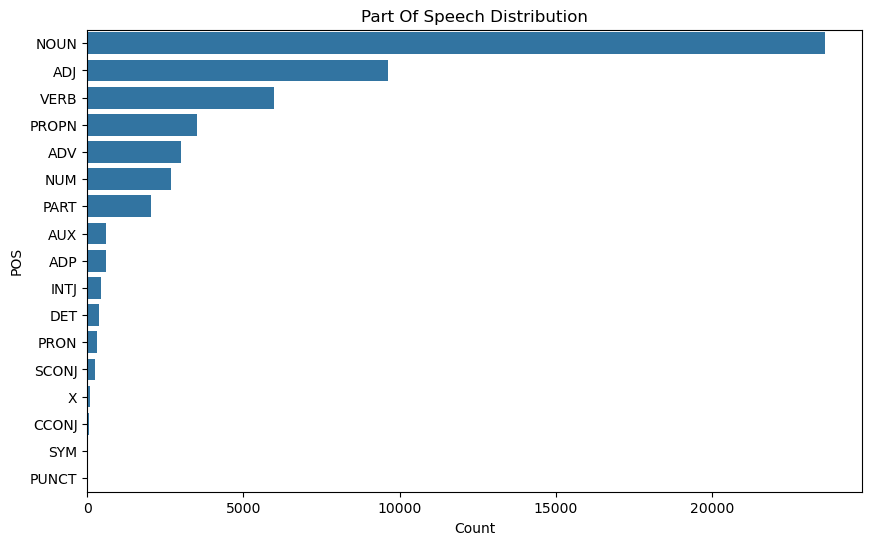

In [67]:
plt.figure(figsize = (10,6))
sns.barplot(data = pos_df, x = "Count", y = "POS")
plt.title("Part Of Speech Distribution")
plt.show()

#### ***TOP ADJECTIVES***

In [68]:
adjectives = []
for text in df["clean_text"]:
    doc = nlp(text)
    for token in doc:
        if token.pos_ == "ADJ":
            adjectives.append(token.text)

adj_df = pd.DataFrame(Counter(adjectives).most_common(20), columns = ["Adjective", "Count"])
adj_df

,Adjective,Count
0,good,1642
1,bad,384
2,mobile,357
3,heavy,246
4,great,238
5,overall,190
6,poor,178
7,nice,143
8,average,138
9,low,129


- Frequent adjectives provide direct evidence of evaluative language used by customers. Positive descriptors such as 'good', 'great', 'excellent', and 'awesome' occur alongside negative descriptors such as 'bad', 'poor', and 'slow'.

#### ***ADJECTIVE PLOT***

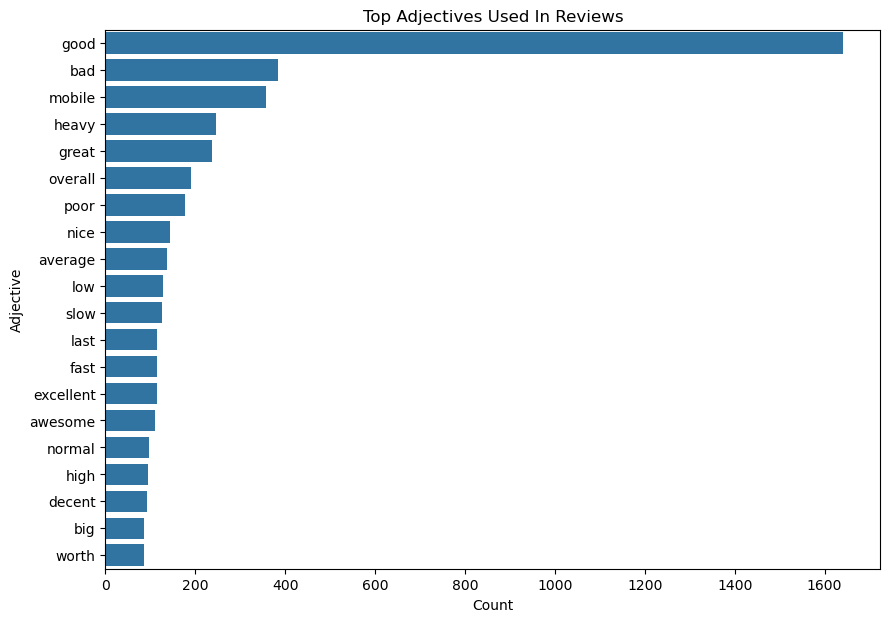

In [69]:
plt.figure(figsize = (10,7))
sns.barplot(data = adj_df, x = "Count", y = "Adjective")
plt.title("Top Adjectives Used In Reviews")
plt.show()

#### ***TOP NOUNS***

In [70]:
nouns = []
for text in df["clean_text"]:
    doc = nlp(text)
    for token in doc:
        if token.pos_ == "NOUN":
            nouns.append(token.text)

noun_df = pd.DataFrame(Counter(nouns).most_common(20), columns = ["Noun", "Count"])
noun_df

,Noun,Count
0,phone,1967
1,camera,1095
2,battery,879
3,quality,711
4,price,465
5,product,451
6,day,360
7,use,339
8,life,314
9,display,278


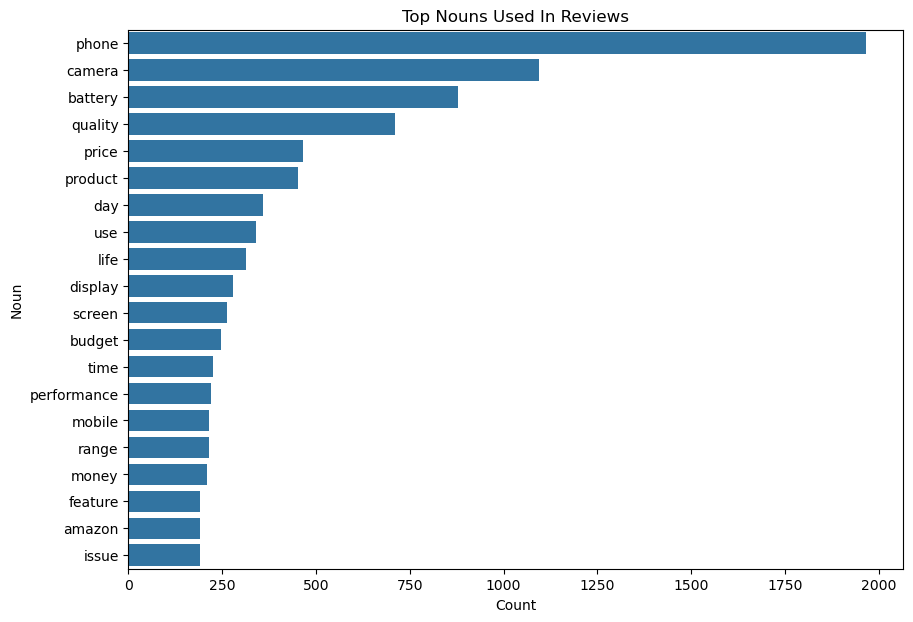

In [71]:
plt.figure(figsize = (10,7))
sns.barplot(data = noun_df, x = "Count", y = "Noun")
plt.title("Top Nouns Used In Reviews")
plt.show()

- Noun analysis helps identify the most discussed product attributes. Frequent nouns such as battery, camera, phone, screen, and charger reveal which product features customers focus on most often.

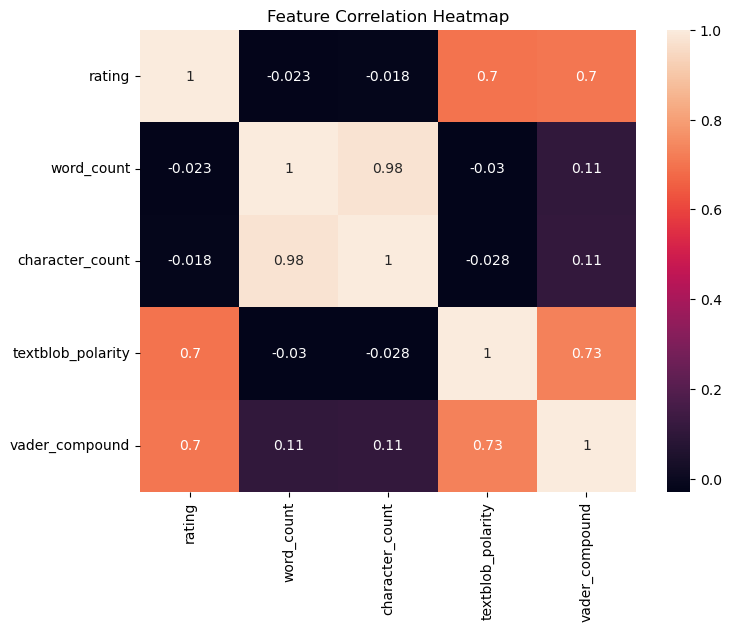

In [72]:
corr_df = df[["rating","word_count","character_count",
              "textblob_polarity","vader_compound"]]

plt.figure(figsize = (8,6))
sns.heatmap(corr_df.corr(), annot = True)
plt.title("Feature Correlation Heatmap")
plt.show()

- The correlation heatmap shows the relationships among customer ratings, review length, TextBlob polarity, and VADER compound scores. A positive correlation between rating and sentiment scores indicates that higher customer ratings tend to be associated with more positive text-based sentiment scores.

#### ***WORDCLOUD -- OVERALL REVIEWS***

In [73]:
all_clean_text = " ".join(df["clean_text"])

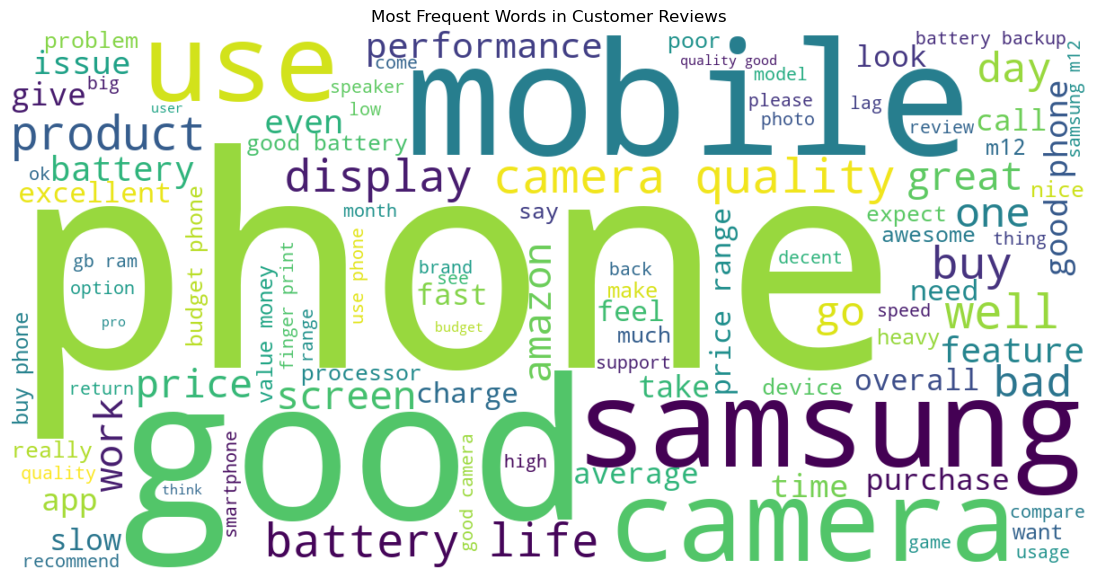

In [74]:
wordcloud = WordCloud(width = 1200,height = 600,background_color = "white",max_words = 100).generate(all_clean_text)

plt.figure(figsize = (14, 7))
plt.imshow(wordcloud, interpolation = "bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Customer Reviews")
plt.show()

#### ***POSITIVE REVIEW WORDCLOUD***

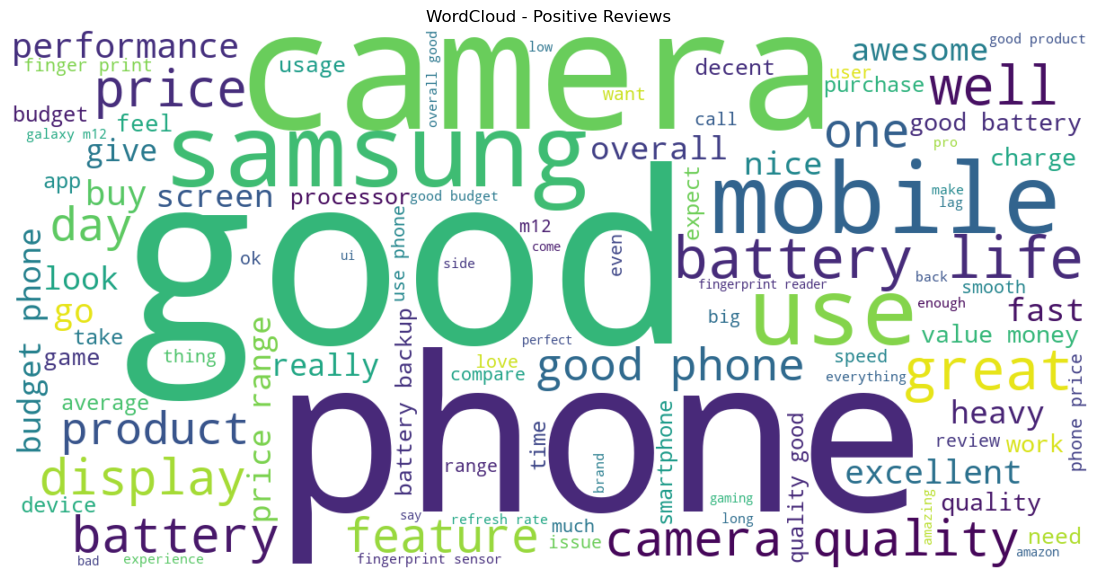

In [75]:
positive_text = " ".join(df.loc[df["sentiment"] == "Positive", "clean_text"])
positive_wordcloud = WordCloud(width = 1200,height = 600,background_color = "white",max_words = 100).generate(positive_text)

plt.figure(figsize = (14, 7))
plt.imshow(positive_wordcloud, interpolation = "bilinear")
plt.axis("off")
plt.title("WordCloud - Positive Reviews")
plt.show()

#### ***NEGATIVE REVIEW WORDCLOUD***

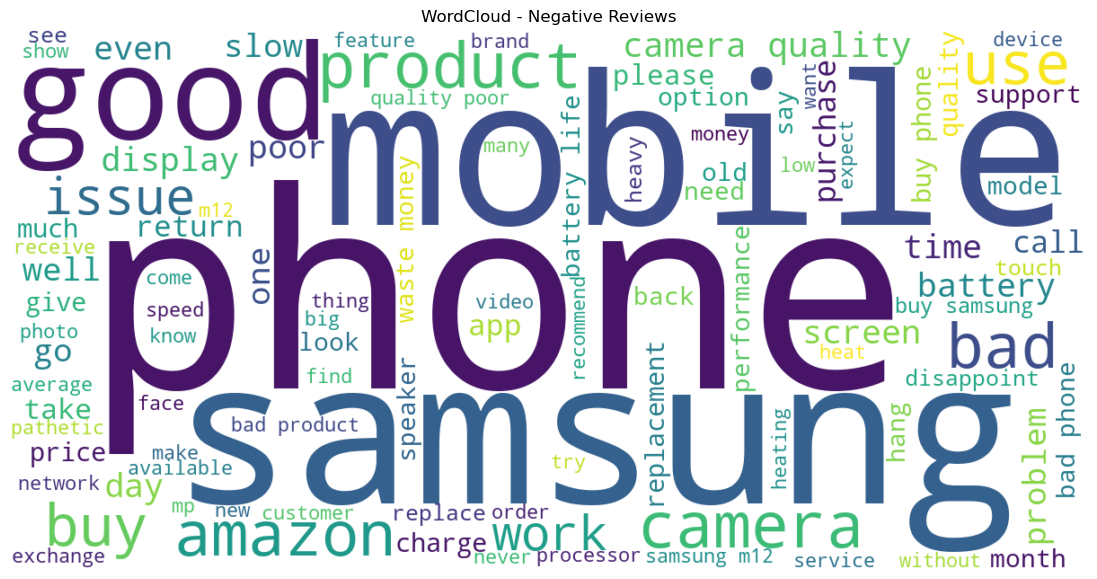

In [76]:
negative_text = " ".join(df.loc[df["sentiment"] == "Negative", "clean_text"])
negative_wordcloud = WordCloud(width = 1200,height = 600,background_color = "white",max_words = 100).generate(negative_text)

plt.figure(figsize = (14, 7))
plt.imshow(negative_wordcloud, interpolation = "bilinear")
plt.axis("off")
plt.title("WordCloud - Negative Reviews")
plt.show()

#### ***NEUTRAL REVIEW WORDCLOUD***

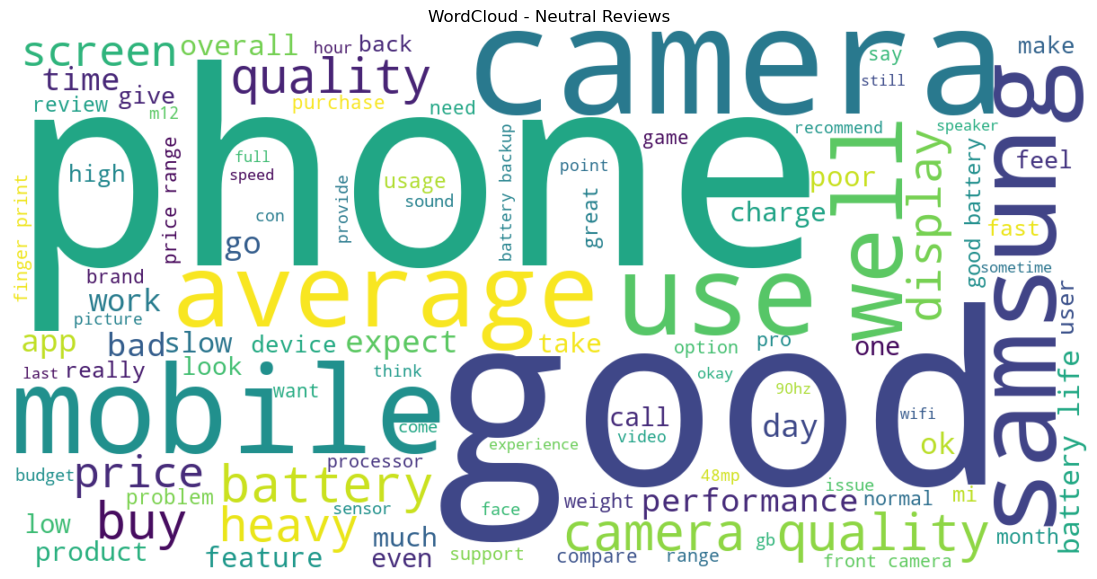

In [77]:
neutral_text = " ".join(df.loc[df["sentiment"] == "Neutral", "clean_text"])
neutral_wordcloud = WordCloud(width = 1200,height = 600,background_color = "white",max_words = 100).generate(neutral_text)

plt.figure(figsize = (14, 7))
plt.imshow(neutral_wordcloud, interpolation = "bilinear")
plt.axis("off")
plt.title("WordCloud - Neutral Reviews")
plt.show()

#### ***TOP WORDS BY SENTIMENT***

In [78]:
def get_top_words_by_sentiment(data, sentiment_name, n = 15):
    text = " ".join(data.loc[data["sentiment"] == sentiment_name, "clean_text"])
    vectorizer = CountVectorizer(stop_words = "english")
    X = vectorizer.fit_transform([text])
    counts = np.asarray(X.sum(axis = 0)).ravel()
    words = vectorizer.get_feature_names_out()
    result = pd.DataFrame({
        "word": words,
        "count": counts
    })
    
    return (result.sort_values("count",ascending = False).head(n))

#### ***POSITIVE***

In [79]:
positive_top_words = get_top_words_by_sentiment(df, "Positive")
positive_top_words

,word,count
1243,good,1259
2077,phone,1020
587,camera,609
448,battery,597
2247,quality,349
2170,price,342
2907,use,337
2431,samsung,327
1823,mobile,235
1630,life,226


#### ***NEGATIVE***

In [80]:
negative_top_words = get_top_words_by_sentiment(df, "Negative")
negative_top_words

,word,count
1665,phone,699
2004,samsung,378
1462,mobile,303
311,bad,303
449,camera,301
436,buy,301
1818,quality,251
1780,product,241
1012,good,205
218,amazon,187


#### ***NEUTRAL***

In [81]:
neutral_top_words = get_top_words_by_sentiment(df, "Neutral")
neutral_top_words

,word,count
991,phone,284
587,good,229
265,camera,188
1073,quality,123
202,battery,120
858,mobile,107
1159,samsung,102
1416,use,92
177,average,75
1041,price,61


#### ***POSITIVE VS NEGATIVE REVIEW LENGTH***

In [82]:
length_summary = (df.groupby("sentiment")[["word_count", "character_count"]].agg(["mean", "median", "min", "max"]))
length_summary

word_count                 character_count                 
                mean median min  max            mean median min   max
sentiment                                                            
Negative   57.957031   51.0   4  308      331.185547  291.5  27  1803
Neutral    61.864322   46.0   6  391      352.919598  261.0  41  2536
Positive   57.484225   48.0   2  297      329.591221  274.0   9  1910

In [83]:
df.to_excel("sentiment_analysis_eda.xlsx", index = False)

## Key EDA Findings

1. The dataset contains 1440 customer reviews and no missing values in the original columns.
2. Two reviews become empty after text cleaning and are removed before model training.
3. Positive reviews are the largest sentiment category.
4. Review length varies significantly across customers.
5. VADER and TextBlob sentiment scores show relationships with customer ratings.
6. Battery, camera, phone, and screen are among the most discussed product features.
7. Positive reviews frequently contain words such as good, excellent, and amazing.
8. Negative reviews frequently contain words such as issue, problem, bad, and poor.
9. Bigram and trigram analysis reveal important customer concerns such as battery life, camera quality, and charging issues.
10. The dataset is suitable for building a baseline machine-learning sentiment classification system using rating-derived sentiment labels.

# ***Modeling Section***

# Model Building and Evaluation

In this section, the cleaned review text will be converted into numerical features using TF-IDF and used to train machine learning models for sentiment classification.

The target variable is the rating-based sentiment:
- Negative
- Neutral
- Positive

In [84]:
empty_reviews = df[df["clean_text"].str.strip() == ""]
print("Empty reviews after cleaning:", len(empty_reviews))

Empty reviews after cleaning: 2


In [85]:
df = df[df["clean_text"].str.strip() != ""].copy()
print("Shape after removing empty reviews:", df.shape)

Shape after removing empty reviews: (1438, 16)


In [86]:
model_df = df[['clean_text', 'sentiment']].copy()

In [87]:
model_df.shape

(1438, 2)

In [88]:
model_df.head()

,clean_text,sentiment
0,horrible product disappoint overall performanc...,Negative
1,camera quality not like 48 megapixel camera qu...,Neutral
2,overall get mobile launch date battery must ap...,Positive
3,big no 1 not work 5 0ghz wifi frequency 2 4ghz...,Negative
4,put money somewhere else not worth buy faulty ...,Negative


- We create a separate DataFrame for modeling.

#### ***CHECK MISSING VALUES***

In [89]:
model_df.isnull().sum()

clean_text    0
sentiment     0
dtype: int64

- Before training, we must make sure that the model doesn't receive missing text or missing target labels.

#### ***CHECK DUPLICATE REVIEWS***

In [90]:
print("Duplicate reviews:", model_df["clean_text"].duplicated().sum())

Duplicate reviews: 0


- Duplicate reviews can cause problems during model evaluation.
- For example, the same review could accidentally appear in both training and testing data.

#### ***REMOVE DUPLICAT***

In [91]:
duplicate_text_labels = (
    model_df.groupby("clean_text")["sentiment"]
    .nunique()
)

conflicting_duplicates = duplicate_text_labels[
    duplicate_text_labels > 1
]

print(
    "Reviews with conflicting sentiment labels:",
    len(conflicting_duplicates)
)

Reviews with conflicting sentiment labels: 0


In [92]:
model_df = model_df.drop_duplicates(
    subset = ["clean_text"]
).reset_index(drop = True)

print("Shape after removing duplicates:", model_df.shape)

Shape after removing duplicates: (1438, 2)


- The same cleaned review may appear multiple times with different rating-derived sentiment labels.
- These conflicting duplicates are checked before removing duplicate review text.
- This helps identify inconsistent labels before duplicate reviews are removed from the modeling dataset.

#### ***CHECK TARGET DISTRIBUTION***

In [93]:
model_df['sentiment'].value_counts()

sentiment
Positive    729
Negative    510
Neutral     199
Name: count, dtype: int64

#### ***TARGET DISTRIBUTION***

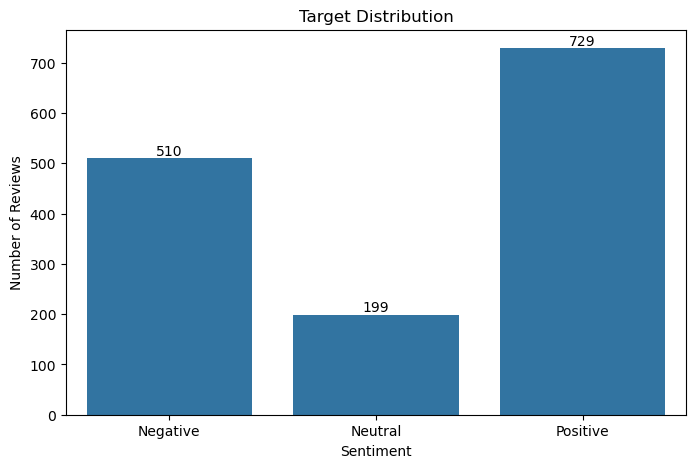

In [94]:
plt.figure(figsize = (8, 5))
ax = sns.countplot(data = model_df, x = 'sentiment', order = ['Negative', 'Neutral', 'Positive'])
plt.title('Target Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

for container in ax.containers:
    ax.bar_label(container)
    
plt.show()

- We're checking the target variable immediately before model training.

#### ***TRAIN-TEST SPLIT***

In [95]:
from sklearn.model_selection import train_test_split

x = model_df['clean_text']
y = model_df['sentiment']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.20, random_state = 42, stratify = y)
print('Training samples:', len(x_train))
print('Test samples:', len(x_test))

Training samples: 1150
Test samples: 288


- The cleaned review text was selected as the feature variable (X), while the sentiment label was selected as the target variable (y).
- The dataset was divided into training and testing sets using an 80:20 ratio. Stratified sampling was used to maintain the same sentiment distribution in both datasets.

#### ***FEATURE EXTRACTION USING TF-IDF***

In [96]:
from sklearn.feature_extraction.text import TfidfVectorizer

#### ***CREATE TF-IDF VECTORIZER***

In [97]:
tfidf = TfidfVectorizer(max_features = 10000, ngram_range = (1, 2), min_df = 2, max_df = 0.95)

#### ***FIT TF-IDF***

In [98]:
x_train_tfidf = tfidf.fit_transform(x_train)
x_test_tfidf = tfidf.transform(x_test)

print("Training TF-IDF shape:", x_train_tfidf.shape)
print("Testing TF-IDF shape:", x_test_tfidf.shape)

Training TF-IDF shape: (1150, 5862)
Testing TF-IDF shape: (288, 5862)


- TF-IDF vectorization was applied after splitting the data. The vectorizer was fitted only on the training dataset and then used to transform both training and testing datasets. This prevents information leakage from the test set.

In [99]:
feature_names = tfidf.get_feature_names_out()
print('Number of TF-IDF Features:', len(feature_names))
print('\nFirst 20 features:')
feature_names[:20]

Number of TF-IDF Features: 5862

First 20 features:


array(['000', '10', '10 000', '10 10', '10 11k', '10 15', '10 day',
       '10 minute', '10 time', '10 year', '100', '100 charge', '100 gb',
       '1000', '10000', '102', '10500', '10999', '10999 good', '10day'],
      dtype=object)

## ***MODEL 1:- LOGISTIC REGRESSION***

In [100]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

In [101]:
lr_model = LogisticRegression(max_iter = 10000, random_state = 42, )
lr_model.fit(x_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'l

#### ***PREDICTION OF LOGISTIC REGRESSION***

In [102]:
y_pred_lr = lr_model.predict(x_test_tfidf)
y_pred_lr[:20]

array(['Negative', 'Positive', 'Positive', 'Positive', 'Negative',
       'Negative', 'Positive', 'Negative', 'Positive', 'Negative',
       'Negative', 'Negative', 'Positive', 'Positive', 'Negative',
       'Positive', 'Negative', 'Negative', 'Positive', 'Negative'],
      dtype=object)

#### ***LOGISTIC REGRESSION EVALUATION***

In [103]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, confusion_matrix

In [104]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, average = 'macro')
recall_lr = recall_score(y_test, y_pred_lr, average = 'macro')
f1_score_lr = f1_score(y_test, y_pred_lr, average = 'macro')

print('Logistic Regression Result:')
print('-' * 35)
print('Accuracy Score:', accuracy_lr)
print('Precision Score', precision_lr)
print('Recall Score', recall_lr)
print('F1 Score', f1_score_lr)

Logistic Regression Result:
-----------------------------------
Accuracy Score: 0.8020833333333334
Precision Score 0.7568526929076063
Recall Score 0.6271510430656281
F1 Score 0.6008473011523323


#### ***CLASSIFICATION REPORT OF LOGISTIC REGRESSION***

In [105]:
print(classification_report(y_test, y_pred_lr, target_names = ['Negative', 'Neutral', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.79      0.87      0.83       102
     Neutral       0.67      0.05      0.09        40
    Positive       0.81      0.96      0.88       146

    accuracy                           0.80       288
   macro avg       0.76      0.63      0.60       288
weighted avg       0.78      0.80      0.75       288



#### ***CONFUSION MATRICX OF LOGISTIC REGRESSION***

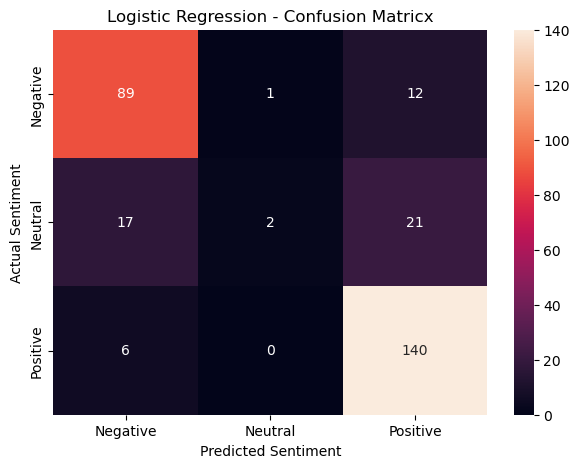

In [106]:
cm_lr = confusion_matrix(y_test, y_pred_lr, labels = ['Negative', 'Neutral', 'Positive'])

plt.figure(figsize = (7, 5))
sns.heatmap(cm_lr, annot = True, fmt = 'd', 
           xticklabels = ["Negative", "Neutral", "Positive"],
           yticklabels = ["Negative", "Neutral", "Positive"]
)
plt.title('Logistic Regression - Confusion Matricx')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

- The confusion matrix shows where the model is making mistakes.
- For example:-
    - Actual Negative → Predicted Negative
    - Actual Negative → Predicted Neutral
    - Actual Negative → Predicted Positive 

## ***MODEL 2:- LINEAR SVM***

In [107]:
from sklearn.svm import LinearSVC

In [108]:
svm_model = LinearSVC(random_state = 42)
svm_model.fit(x_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adj

- The Linear SVM learns boundaries between:
    - Negative
    - Neutral
    - Positive
- using the TF-IDF feature space.

#### ***SVM PREDICTION***

In [109]:
y_pred_svm = svm_model.predict(x_test_tfidf)
y_pred_svm[:20]

array(['Negative', 'Positive', 'Positive', 'Positive', 'Negative',
       'Negative', 'Positive', 'Negative', 'Positive', 'Negative',
       'Neutral', 'Negative', 'Neutral', 'Positive', 'Negative',
       'Positive', 'Negative', 'Negative', 'Positive', 'Negative'],
      dtype=object)

#### ***SVM EVALUATION***

In [110]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, average = 'macro')
recall_svm = recall_score(y_test, y_pred_svm, average = 'macro')
f1_score_svm = f1_score(y_test, y_pred_svm, average = 'macro')

print('Linear SVM Results:')
print('--' * 20)
print('Accuracy Score:', accuracy_svm)
print('Precision Score:', precision_svm)
print('Recall Score:', recall_svm)
print('F1 Score:', f1_score_svm)

Linear SVM Results:
----------------------------------------
Accuracy Score: 0.7847222222222222
Precision Score: 0.6829721940618758
Recall Score: 0.64092130002686
F1 Score: 0.6331839134341185


#### ***SVM CLASSIFICATION REPORT***

In [111]:
print(classification_report(y_test, y_pred_svm, target_names = ['Negative', 'Neutral', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.74      0.88      0.80       102
     Neutral       0.46      0.15      0.23        40
    Positive       0.85      0.89      0.87       146

    accuracy                           0.78       288
   macro avg       0.68      0.64      0.63       288
weighted avg       0.76      0.78      0.76       288



#### ***SVM CONFUSION MATRICX***

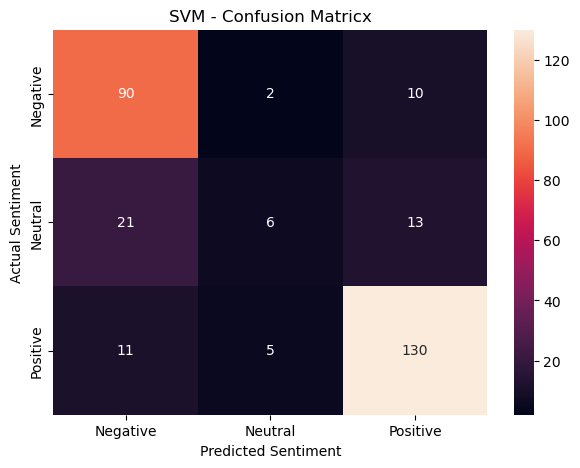

In [112]:
cm_svm = confusion_matrix(y_test, y_pred_svm, labels = ['Negative', 'Neutral', 'Positive'])

plt.figure(figsize = (7, 5))
sns.heatmap(cm_svm, annot = True, fmt = 'd', 
           xticklabels = ["Negative", "Neutral", "Positive"],
           yticklabels = ["Negative", "Neutral", "Positive"]
)
plt.title('SVM - Confusion Matricx')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

## ***MODEL 3:- DECISION TREE***

In [113]:
from sklearn.tree import DecisionTreeClassifier

In [114]:
de_model = DecisionTreeClassifier(random_state = 42)
de_model.fit(x_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

#### ***DECISION TREE PRIDICTION***

In [115]:
y_pred_de = de_model.predict(x_test_tfidf)
y_pred_de[:20]

array(['Negative', 'Neutral', 'Positive', 'Positive', 'Negative',
       'Neutral', 'Positive', 'Positive', 'Positive', 'Negative',
       'Negative', 'Positive', 'Positive', 'Positive', 'Negative',
       'Positive', 'Positive', 'Neutral', 'Positive', 'Negative'],
      dtype=object)

#### ***DECISION TREE EVALUATION***

In [116]:
accuracy_de = accuracy_score(y_test, y_pred_de)
precision_de = precision_score(y_test, y_pred_de, average = 'macro')
recall_de = recall_score(y_test, y_pred_de, average = 'macro')
f1_score_de = f1_score(y_test, y_pred_de, average = 'macro')

print('Decision Tree Results:')
print('--' * 20)
print('Accuracy Score:', accuracy_de)
print('Precision Score:', precision_de)
print('Recall Score:', recall_de)
print('F1 Score:', f1_score_de)

Decision Tree Results:
----------------------------------------
Accuracy Score: 0.6388888888888888
Precision Score: 0.528446674098848
Recall Score: 0.5213940370668816
F1 Score: 0.5240447418128854


#### ***DECISION TREE CLASSIFICATION REPORT***

In [117]:
print(classification_report(y_test, y_pred_de, target_names = ['Negative', 'Neutral', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.72      0.65      0.68       102
     Neutral       0.15      0.15      0.15        40
    Positive       0.72      0.77      0.74       146

    accuracy                           0.64       288
   macro avg       0.53      0.52      0.52       288
weighted avg       0.64      0.64      0.64       288



#### ***DECISION TREE CONFUSION MERIX***

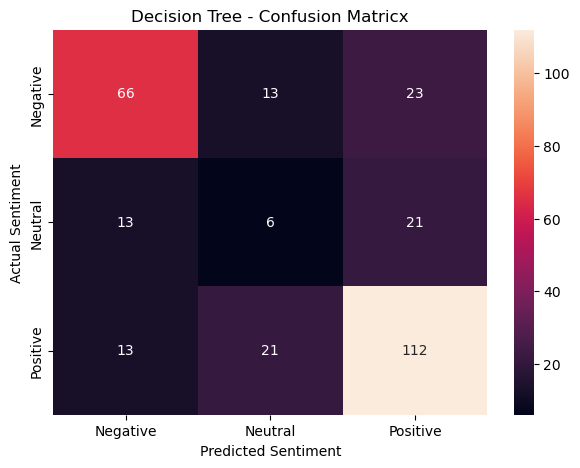

In [118]:
de_svm = confusion_matrix(y_test, y_pred_de, labels = ['Negative', 'Neutral', 'Positive'])

plt.figure(figsize = (7, 5))
sns.heatmap(de_svm, annot = True, fmt = 'd', 
           xticklabels = ["Negative", "Neutral", "Positive"],
           yticklabels = ["Negative", "Neutral", "Positive"]
)
plt.title('Decision Tree - Confusion Matricx')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

## ***MODEL 4:- RANDOM FOREST***

In [119]:
from sklearn.ensemble import RandomForestClassifier

In [120]:
rf_model = RandomForestClassifier(n_estimators = 200, random_state = 42, n_jobs = -1)
rf_model.fit(x_train_tfidf, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

#### ***RANDOM FOREST PRIDICTION***

In [121]:
y_pred_rf = rf_model.predict(x_test_tfidf)
y_pred_rf[:20]

array(['Negative', 'Positive', 'Positive', 'Positive', 'Negative',
       'Positive', 'Positive', 'Positive', 'Positive', 'Negative',
       'Negative', 'Positive', 'Positive', 'Positive', 'Negative',
       'Positive', 'Negative', 'Negative', 'Positive', 'Negative'],
      dtype=object)

#### ***RANDOM FOREST EVALUATION***

In [122]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average = 'macro')
recall_rf = recall_score(y_test, y_pred_rf, average = 'macro')
f1_score_rf = f1_score(y_test, y_pred_rf, average = 'macro')

print('Random Forest Results:')
print('--' * 20)
print('Accuracy Score:', accuracy_rf)
print('Precision Score:', precision_rf)
print('Recall Score:', recall_rf)
print('F1 Score:', f1_score_rf)

Random Forest Results:
----------------------------------------
Accuracy Score: 0.78125
Precision Score: 0.8538263995891114
Recall Score: 0.6044475781180052
F1 Score: 0.5715301355361823


#### ***RANDOM FOREST CLASSIFICATION REPORT***

In [123]:
print(classification_report(y_test, y_pred_rf, target_names = ['Negative', 'Neutral', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.78      0.84      0.81       102
     Neutral       1.00      0.03      0.05        40
    Positive       0.78      0.95      0.85       146

    accuracy                           0.78       288
   macro avg       0.85      0.60      0.57       288
weighted avg       0.81      0.78      0.73       288



#### ***RANDOM FOREST CONFUSION METRIX***

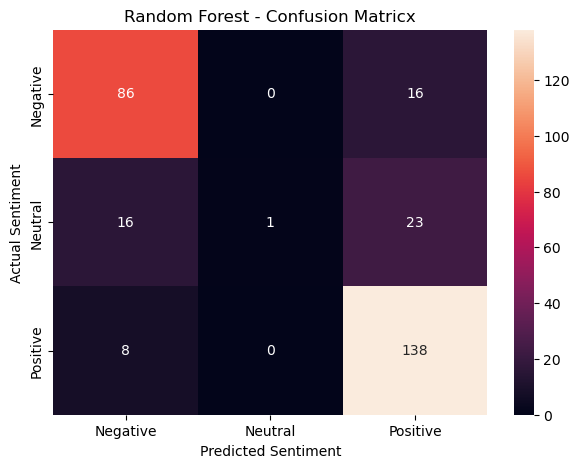

In [124]:
rf_svm = confusion_matrix(y_test, y_pred_rf, labels = ['Negative', 'Neutral', 'Positive'])

plt.figure(figsize = (7, 5))
sns.heatmap(rf_svm, annot = True, fmt = 'd', 
           xticklabels = ["Negative", "Neutral", "Positive"],
           yticklabels = ["Negative", "Neutral", "Positive"]
)
plt.title('Random Forest - Confusion Matricx')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

## ***MODEL 5:- MULTINOMIAL NAIVE BAYES***

In [125]:
from sklearn.naive_bayes import MultinomialNB

In [126]:
nav_model = MultinomialNB()
nav_model.fit(x_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[408.,159.,583.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.04,-1.98,-0.68]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U8](3,)","['Negative','Neutral','Positive']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 5862)","[[0. ,3.23,0. ,...,0.94,0.2 ,0.22], [0.2 ,0.42,0. ,...,0.63,0.19,0. ], [1.35,4.34,0.77,...,1.44,0.2 ,0.16]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 5862)","[[-9.01,-7.57,-9.01,...,-8.35,-8.83,-8.81], [-8.64,-8.47,-8.83,...,-8.34,-8.65,-8.83], [-8.28,-7.46,-8.56,...,-8.24,-8.95,-8.99]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5862


#### ***MULTINOMIAL NAIVE BAYES PRIDICTION***

In [127]:
y_pred_nav = nav_model.predict(x_test_tfidf)
y_pred_nav[:20]

array(['Negative', 'Positive', 'Positive', 'Positive', 'Negative',
       'Positive', 'Positive', 'Positive', 'Positive', 'Negative',
       'Negative', 'Positive', 'Positive', 'Positive', 'Negative',
       'Positive', 'Positive', 'Negative', 'Positive', 'Negative'],
      dtype='<U8')

#### ***MULTINOMIAL NAIVE BAYES EVALUATION***

In [128]:
accuracy_nav = accuracy_score(y_test, y_pred_nav)
precision_nav = precision_score(y_test, y_pred_nav, average = 'macro')
recall_nav = recall_score(y_test, y_pred_nav, average = 'macro')
f1_score_nav = f1_score(y_test, y_pred_nav, average = 'macro')

print('Multinomial Naive Bayes Results:')
print('--' * 20)
print('Accuracy Score:', accuracy_nav)
print('Precision Score:', precision_nav)
print('Recall Score:', recall_nav)
print('F1 Score:', f1_score_nav)

Multinomial Naive Bayes Results:
----------------------------------------
Accuracy Score: 0.7534722222222222
Precision Score: 0.518499456739292
Recall Score: 0.5673292147909392
F1 Score: 0.5341526513476561


#### ***MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT***

In [129]:
print(classification_report(y_test, y_pred_nav, target_names = ['Negative', 'Neutral', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.84      0.72      0.77       102
     Neutral       0.00      0.00      0.00        40
    Positive       0.72      0.99      0.83       146

    accuracy                           0.75       288
   macro avg       0.52      0.57      0.53       288
weighted avg       0.66      0.75      0.69       288



#### ***MULTINOMIAL NAIVE BAYES CONFUSION METRIX***

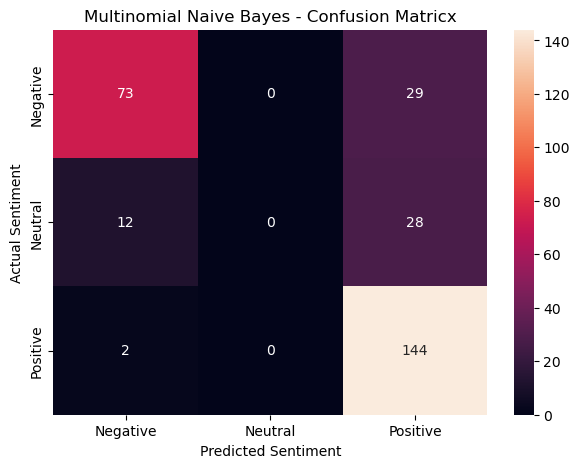

In [130]:
nav_svm = confusion_matrix(y_test, y_pred_nav, labels = ['Negative', 'Neutral', 'Positive'])

plt.figure(figsize = (7, 5))
sns.heatmap(nav_svm, annot = True, fmt = 'd', 
           xticklabels = ["Negative", "Neutral", "Positive"],
           yticklabels = ["Negative", "Neutral", "Positive"]
)
plt.title('Multinomial Naive Bayes - Confusion Matricx')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

#### ***MODEL COMPARISON***

In [131]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Linear SVM', 'Decision Tree', 'Random Forest', 'Multinomial Naive Bayes'],
    'Accuracy': [accuracy_lr, accuracy_svm, accuracy_de, accuracy_rf, accuracy_nav],
    'Precision': [precision_lr, precision_svm, precision_de, precision_rf, precision_nav],
    'Recall': [recall_lr, recall_svm, recall_de, recall_rf, recall_nav],
    'F1 Score': [f1_score_lr, f1_score_svm, f1_score_de, f1_score_rf, f1_score_nav]
})

results = results.sort_values(by = 'Accuracy', ascending = False)
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.802083,0.756853,0.627151,0.600847
1,Linear SVM,0.784722,0.682972,0.640921,0.633184
3,Random Forest,0.781250,0.853826,0.604448,0.571530
4,Multinomial Naive Bayes,0.753472,0.518499,0.567329,0.534153
2,Decision Tree,0.638889,0.528447,0.521394,0.524045


#### ***ACCURACY CHART***

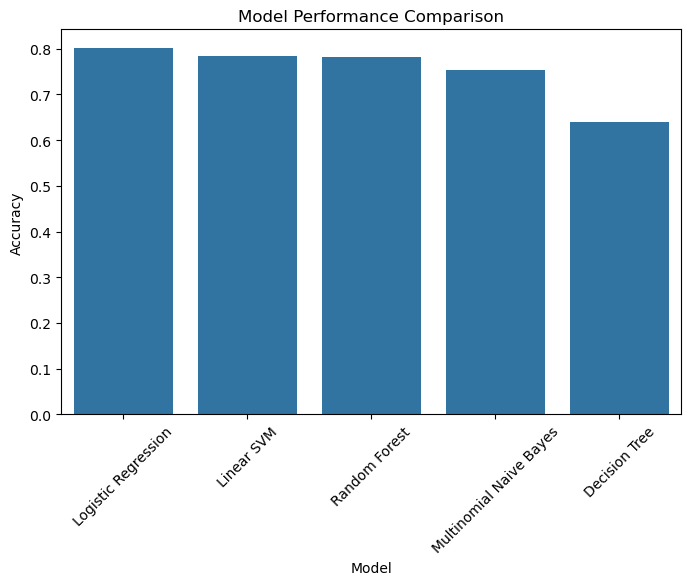

In [132]:
plt.figure(figsize = (8, 5))
sns.barplot(data = results, x = 'Model', y = 'Accuracy')
plt.title('Model Performance Comparison')
plt.xticks(rotation = 45)
plt.show()

In [133]:
best_model_name = results.iloc[0]["Model"]
best_accuracy = results.iloc[0]["Accuracy"]
print("Baseline Model with Highest Accuracy:", best_model_name)
print("Accuracy:", best_accuracy)

Baseline Model with Highest Accuracy: Logistic Regression
Accuracy: 0.8020833333333334


## ***CROSS VALIDATION***

In [134]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [135]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

#### ***LOGISTIC REGRESSION CROSS VALIDATION***

In [136]:
lr_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 10000,
        ngram_range = (1, 2),
        min_df = 2, 
        max_df = 0.95
    )),
    ('model', LogisticRegression(
        max_iter = 10000,
        random_state = 42
    ))
])

lr_cv_scores = cross_val_score(lr_pipeline, x_train, y_train, cv = cv, scoring = 'f1_macro')

print('Logistic Regression CV F1 Scores:')
print(lr_cv_scores)
print('\nMean CV F1 Score:', round(lr_cv_scores.mean(), 4))
print('Standard Deviation:', round(lr_cv_scores.std(), 4))

Logistic Regression CV F1 Scores:
[0.57128691 0.58084815 0.5794527  0.55897401 0.61121449]

Mean CV F1 Score: 0.5804
Standard Deviation: 0.0173


#### ***SVM CROSS VALIDATION***

In [137]:
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 10000,
        ngram_range = (1, 2),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', LinearSVC(
        random_state = 42
    ))
])

svm_cv_scores = cross_val_score(svm_pipeline, x_train, y_train, cv = cv, scoring = 'f1_macro', n_jobs = -1)

print('SVM CV F1 Scores:')
print(svm_cv_scores)
print('\nMean CV F1 Score:', round(svm_cv_scores.mean(), 4))
print('Standard Deviation:', round(svm_cv_scores.std(), 4))

SVM CV F1 Scores:
[0.59537037 0.63736477 0.6641919  0.63339836 0.68304812]

Mean CV F1 Score: 0.6427
Standard Deviation: 0.0298


#### ***DECISION TREE CROSS VALIDATION***

In [138]:
dt_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 10000,
        ngram_range = (1, 3),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', DecisionTreeClassifier(
        random_state = 42
    ))
])

dt_cv_scores = cross_val_score(dt_pipeline, x_train, y_train, cv = cv, scoring = 'f1_macro')
print('Decision Tree CV F1 Scores:')
print(dt_cv_scores)
print('\nMean CV F1 Score:', round(dt_cv_scores.mean(), 4))
print('Standard Deviation:', round(dt_cv_scores.std(), 4))

Decision Tree CV F1 Scores:
[0.59662013 0.55900437 0.5335479  0.54166242 0.53507207]

Mean CV F1 Score: 0.5532
Standard Deviation: 0.0235


#### ***RANDOM FOREST CROSS VALIDATION***

In [139]:
rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 10000,
        ngram_range = (1, 3),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', RandomForestClassifier(
        random_state = 42,
        n_jobs = -1
    ))
])

rf_cv_scores = cross_val_score(rf_pipeline, x_train, y_train, cv = cv, scoring = 'f1_macro')
print('Random Forest CV F1 Scores:')
print(rf_cv_scores)
print('\nMean CV F1 Score:', round(rf_cv_scores.mean(), 4))
print('Standard Deviation:', round(rf_cv_scores.std(), 4))

Random Forest CV F1 Scores:
[0.5662088  0.56442241 0.55007156 0.55242771 0.57522286]

Mean CV F1 Score: 0.5617
Standard Deviation: 0.0093


#### ***MULTINOMIAL NAIVE BAYES CROSS VALIDATION***

In [140]:
nav_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 10000,
        ngram_range = (1, 3),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', MultinomialNB())
])

nav_cv_scores = cross_val_score(nav_pipeline, x_train, y_train, cv = cv, scoring = 'f1_macro')
print('Multinomial naive Bayes CV F1 Scores:')
print(nav_cv_scores)
print('\nMean CV F1 Score:', round(nav_cv_scores.mean(), 4))
print('Standard Deviation:', round(nav_cv_scores.std(), 4))

Multinomial naive Bayes CV F1 Scores:
[0.55470304 0.54532164 0.53320544 0.53969624 0.52773893]

Mean CV F1 Score: 0.5401
Standard Deviation: 0.0094


Five-fold stratified cross-validation was used to evaluate model stability.

In each fold:
- The training portion is used to fit TF-IDF and the model.
- The validation portion is used to evaluate the model.
- Each fold gets one opportunity to act as validation data.

TF-IDF is included inside the Pipeline so that it is fitted separately within each training fold. This prevents information leakage during cross-validation.

Macro F1-score is used as the evaluation metric because the sentiment classes are imbalanced. Macro F1 gives equal importance to Negative, Neutral, and Positive classes.

The same Macro F1-score is used during hyperparameter tuning and final model selection for consistency.

#### ***Hyperparameter Tuning***

In [141]:
from sklearn.model_selection import GridSearchCV

#### ***TUNE LOGISTIC REGRESSION MODEL***

In [142]:
lr_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 15000,
        ngram_range = (1, 3),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', LogisticRegression(
        max_iter = 10000,
        random_state = 42,
        class_weight = 'balanced'
    ))
])


lr_param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced', {"Negative": 1.0,"Neutral": 2.0, "Positive": 1.0}]
}

lr_grid = GridSearchCV(estimator = lr_pipeline, param_grid = lr_param_grid, cv = cv, scoring = 'f1_macro', n_jobs = -1)
lr_grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [143]:
print('Best Logistic Regression Parameters:')
print(lr_grid.best_params_)
print('\nBest Cross Validation F1 Score:')
print(round(lr_grid.best_score_, 4))

Best Logistic Regression Parameters:
{'model__C': 0.1, 'model__class_weight': 'balanced'}

Best Cross Validation F1 Score:
0.6726


#### ***TUNE LINEAR SVM MODEL***

In [144]:
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 15000,
        ngram_range = (1, 3),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', LinearSVC(
        random_state = 42,
        class_weight = 'balanced'
    ))
])



svm_param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced', {"Negative": 1.0,"Neutral": 2.0, "Positive": 1.0}]
}

svm_grid = GridSearchCV(estimator = svm_pipeline, param_grid = svm_param_grid, cv = cv, scoring = 'f1_macro', n_jobs = -1)
svm_grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [145]:
print('Best Linear SVM Parameters:')
print(svm_grid.best_params_)
print('\nBest Cross Validation F1 Score:')
print(round(svm_grid.best_score_, 4))

Best Linear SVM Parameters:
{'model__C': 1, 'model__class_weight': 'balanced'}

Best Cross Validation F1 Score:
0.6561


#### ***TUNE DECISION TREE***

In [146]:
de_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 15000,
        ngram_range = (1, 3),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', DecisionTreeClassifier(
        random_state = 42,
    ))
])



de_param_grid = {
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': [None, 'balanced', {"Negative": 1.0,"Neutral": 2.0, "Positive": 1.0}]
}

de_grid = GridSearchCV(estimator = de_pipeline, param_grid = de_param_grid, cv = cv, scoring = 'f1_macro', n_jobs = -1)
de_grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced', ...], 'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-valid

In [147]:
print('Best Decision Tree Parameters:')
print(de_grid.best_params_)
print('\nBest Cross Validation F1 Score:')
print(round(de_grid.best_score_, 4))

Best Decision Tree Parameters:
{'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}

Best Cross Validation F1 Score:
0.5779


#### ***TUNE RANDOM FOREST***

In [148]:
rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 15000,
        ngram_range = (1, 3),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', RandomForestClassifier(
        random_state = 42,
        n_jobs = -1
    ))
])



rf_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 20, 30],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2],
    'model__class_weight': [None, 'balanced', {"Negative": 1.0,"Neutral": 2.0, "Positive": 1.0}]
}

rf_grid = GridSearchCV(estimator = rf_pipeline, param_grid = rf_param_grid, cv = cv, scoring = 'f1_macro', n_jobs = -1)
rf_grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced', ...], 'model__max_depth': [None, 20, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated 

In [149]:
print('Best Random Forest Parameters:')
print(rf_grid.best_params_)
print('\nBest Cross Validation F1 Score:')
print(round(rf_grid.best_score_, 4))

Best Random Forest Parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 100}

Best Cross Validation F1 Score:
0.6564


#### ***TUNE MULTINOMIAL NAIEVE BAYES***

In [150]:
nav_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features = 15000,
        ngram_range = (1, 3),
        min_df = 2,
        max_df = 0.95
    )),
    ('model', MultinomialNB())
])



nav_param_grid = {
    'model__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
}

nav_grid = GridSearchCV(estimator = nav_pipeline, param_grid = nav_param_grid, cv = cv, scoring = 'f1_macro', n_jobs = -1)
nav_grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...inomialNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inf

In [151]:
print('Best Multinomial Naive Bayes Parameters:')
print(nav_grid.best_params_)
print('\nBest Cross Validation F1 Score:')
print(round(nav_grid.best_score_, 4))

Best Multinomial Naive Bayes Parameters:
{'model__alpha': 0.01}

Best Cross Validation F1 Score:
0.5986


- GridSearchCV is used to search for the best combination of model hyperparameters.

- Different hyperparameter values are tested for each classification algorithm. For example, C is tuned for Logistic Regression and Linear SVM, tree-related parameters are tuned for Decision Tree and Random Forest, and alpha is tuned for Multinomial Naive Bayes.

- Five-fold stratified cross-validation is used during tuning, and Macro F1-score is used as the scoring metric.

- The parameter combination with the highest Macro F1-score is selected as the best configuration for each model.

### Why Class Weight is Tuned

The sentiment classes are not perfectly balanced, with Neutral reviews having fewer samples than Positive and Negative reviews.

Class weights allow the model to give more importance to underrepresented classes during training.

The tuning process compares different class-weight strategies, including balanced weighting and an explicit higher weight for the Neutral class.

In [152]:
best_lr = lr_grid.best_estimator_
best_svm = svm_grid.best_estimator_
best_de = de_grid.best_estimator_
best_rf = rf_grid.best_estimator_
best_nav = nav_grid.best_estimator_

y_pred_lr_tuned = best_lr.predict(x_test)
y_pred_svm_tuned = best_svm.predict(x_test)
y_pred_de_tuned = best_de.predict(x_test)
y_pred_rf_tuned = best_rf.predict(x_test)
y_pred_nav_tuned = best_nav.predict(x_test)

#### ***FINAL COMPARISON***

In [153]:
final_results = pd.DataFrame({
    'Model': ['Tuned Logistic Regression',
              'Tuned Linear SVM',
              'Tuned Decision Tree',
              'Tuned Random Forest',
              'Tuned Multinomial Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr_tuned),
        accuracy_score(y_test, y_pred_svm_tuned),
        accuracy_score(y_test, y_pred_de_tuned),
        accuracy_score(y_test, y_pred_rf_tuned),
        accuracy_score(y_test, y_pred_nav_tuned)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr_tuned, average = 'macro'), 
        precision_score(y_test, y_pred_svm_tuned, average = 'macro'),
        precision_score(y_test, y_pred_de_tuned, average = 'macro'),
        precision_score(y_test, y_pred_rf_tuned, average = 'macro'),
        precision_score(y_test, y_pred_nav_tuned, average = 'macro')
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr_tuned, average = 'macro'),
        recall_score(y_test, y_pred_svm_tuned, average = 'macro'),
        recall_score(y_test, y_pred_de_tuned, average = 'macro'),
        recall_score(y_test, y_pred_rf_tuned, average = 'macro'),
        recall_score(y_test, y_pred_nav_tuned, average = 'macro')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr_tuned, average = 'macro'),
        f1_score(y_test, y_pred_svm_tuned, average = 'macro'),
        f1_score(y_test, y_pred_de_tuned, average = 'macro'),
        f1_score(y_test, y_pred_rf_tuned, average = 'macro'),
        f1_score(y_test, y_pred_nav_tuned, average = 'macro')
    ]
})

final_results = final_results.sort_values(by = 'F1 Score', ascending = False).reset_index(drop = True)
final_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Logistic Regression,0.7882,0.6966,0.6967,0.6956
1,Tuned Random Forest,0.7882,0.6853,0.6766,0.6781
2,Tuned Linear SVM,0.7847,0.6717,0.6571,0.6556
3,Tuned Multinomial Naive Bayes,0.7604,0.6471,0.6100,0.6047
4,Tuned Decision Tree,0.6250,0.4919,0.4982,0.4932


After hyperparameter tuning, the best model configuration is evaluated on the untouched test dataset.

The test dataset was not used during model training or hyperparameter selection. Therefore, it provides an independent estimate of how the final model performs on unseen reviews.

The main evaluation metrics are:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score

Macro averaging gives equal importance to each sentiment class, which is useful because the Neutral class has fewer examples than the Positive and Negative classes.

In [154]:
tuned_cv_results = pd.DataFrame({
    'Model': [
        'Tuned Logistic Regression',
        'Tuned Linear SVM',
        'Tuned Decision Tree',
        'Tuned Random Forest',
        'Tuned Multinomial Naive Bayes'
    ],
    'CV Macro F1': [
        lr_grid.best_score_,
        svm_grid.best_score_,
        de_grid.best_score_,
        rf_grid.best_score_,
        nav_grid.best_score_
    ]
})

tuned_cv_results = tuned_cv_results.sort_values(
    by = 'CV Macro F1',
    ascending = False
).reset_index(drop = True)

tuned_cv_results.round(4)

,Model,CV Macro F1
0,Tuned Logistic Regression,0.6726
1,Tuned Random Forest,0.6564
2,Tuned Linear SVM,0.6561
3,Tuned Multinomial Naive Bayes,0.5986
4,Tuned Decision Tree,0.5779


In [155]:
best_model_name = tuned_cv_results.iloc[0]["Model"]
best_cv_f1 = tuned_cv_results.iloc[0]["CV Macro F1"]

print("Selected Model based on Cross-Validated Macro F1:", best_model_name)
print("CV Macro F1 Score:", round(best_cv_f1, 4))

Selected Model based on Cross-Validated Macro F1: Tuned Logistic Regression
CV Macro F1 Score: 0.6726


- The final model was selected based on Macro F1-score because Macro F1 gives equal importance to Negative, Neutral, and Positive sentiment classes.

In [156]:
if best_model_name == "Tuned Logistic Regression":
    final_prediction = y_pred_lr_tuned
    final_estimator = best_lr
elif best_model_name == "Tuned Linear SVM":
    final_prediction = y_pred_svm_tuned
    final_estimator = best_svm
elif best_model_name == "Tuned Decision Tree":
    final_prediction = y_pred_de_tuned
    final_estimator = best_de
elif best_model_name == "Tuned Random Forest":
    final_prediction = y_pred_rf_tuned
    final_estimator = best_rf
else:
    final_prediction = y_pred_nav_tuned
    final_estimator = best_nav

### Final Model Selection

All five tuned classification models are compared using their cross-validated Macro F1-scores.

The model with the highest cross-validated Macro F1-score is selected as the final model.

The selected model is then evaluated on the untouched test dataset using Accuracy, Macro Precision, Macro Recall, and Macro F1-score.

#### ***FINAL CONFUSION METRICX***

In [157]:
cm = confusion_matrix(y_test, final_prediction, labels = ['Negative', 'Neutral', 'Positive'])
print(cm)

[[ 89   7   6]
 [ 14  15  11]
 [  9  14 123]]


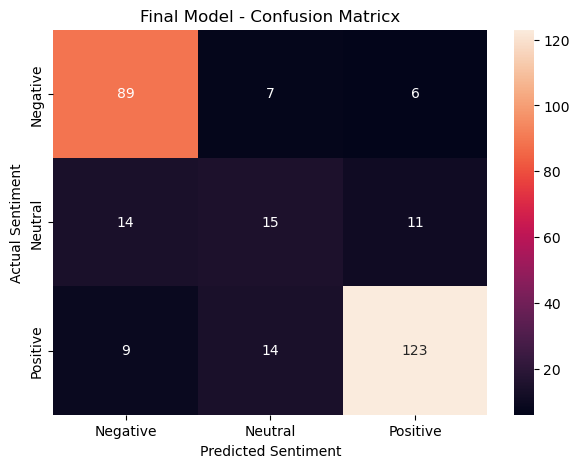

In [158]:
plt.figure(figsize = (7, 5))
sns.heatmap(cm, annot = True, fmt = 'd', xticklabels = ["Negative", "Neutral", "Positive"],
            yticklabels = ["Negative", "Neutral", "Positive"])
plt.title('Final Model - Confusion Matricx')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

#### ***FINAL CLASSIFICATION REPORT***

In [159]:
print(classification_report(y_test, final_prediction, target_names = ['Negative', 'Neutral', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.79      0.87      0.83       102
     Neutral       0.42      0.38      0.39        40
    Positive       0.88      0.84      0.86       146

    accuracy                           0.79       288
   macro avg       0.70      0.70      0.70       288
weighted avg       0.78      0.79      0.79       288



### Final Model Observations

The selected Logistic Regression model performs strongly on the Negative and Positive classes, while the Neutral class remains more challenging and has a lower F1-score.

The Neutral class has fewer examples than the Positive and Negative classes. Neutral reviews can also contain language that overlaps with both positive and negative sentiment.

Therefore, the model should be considered a practical sentiment classification system rather than a perfect sentiment detector.

In [160]:
sample_reviews = [
    "The product is average and works as expected.",
    "It is neither good nor bad, just okay.",
    "The product is fine, but nothing special.",
    "It works as described, but there is nothing impressive about it.",
    "The product is okay for the price."
]

sample_clean = [
    clean_text(x)
    for x in sample_reviews
]

predictions = final_estimator.predict(sample_clean)

for review, prediction in zip(sample_reviews, predictions):
    print("Review:", review)
    print("Prediction:", prediction)
    print('-' * 60)

Review: The product is average and works as expected.
Prediction: Neutral
------------------------------------------------------------
Review: It is neither good nor bad, just okay.
Prediction: Negative
------------------------------------------------------------
Review: The product is fine, but nothing special.
Prediction: Negative
------------------------------------------------------------
Review: It works as described, but there is nothing impressive about it.
Prediction: Negative
------------------------------------------------------------
Review: The product is okay for the price.
Prediction: Positive
------------------------------------------------------------


### Sample Prediction Testing

A few new example reviews are passed through the same preprocessing and final model to verify that the model can generate sentiment predictions for new text.

Neutral-style examples are also included because Neutral is the more challenging sentiment class in the evaluation results.

In [161]:
import joblib

joblib.dump(final_estimator, 'sentiment_model.pkl')
print('Final Model Saved Successfully.')
print('Model:', best_model_name)

Final Model Saved Successfully.
Model: Tuned Logistic Regression
